# 05.01 — HRV data inspection

**Stage:** `data_inspection` · **Notebook 1 of 3**  
**Scope:** descriptive inspection of the seven recorded HRV / cardiac interval variables, using the final analytical cohort from preprocessing.  
**Input:** `outputs/dataset_final.csv` (current release **402 source records**).  
**Outputs:** descriptive CSVs, **informative multipanel figures**, `README_05_hrv_inspection.md`, and `05_hrv_inspection_results.md`.

## Analytical boundaries

- Inspect the distribution and descriptive relationships of the recorded HRV variables only.
- Five main HRV indicators: **SDNN, RMSSD, HF, LF, VLF**. Two complementary measures: **mean RR** and **mean HR**.
- **No** cohort modification, imputation, correction, outlier removal, standardization for modeling, hypothesis testing, clinical interpretation, predictive modeling, or clustering.
- Tukey IQR fences, normal Q–Q views, and log1p views are **descriptive visualization tools**, not data-quality rules.
- No age, sex, BMI, blood pressure, or other non-HRV factor comparisons in this notebook. Those belong to subsequent stages.
- **Multipanel principle:** plots are grouped by scientific purpose; the notebook does not export individual PNGs for each measure/view combination.

This notebook is intended to live at `notebooks/data_inspection/05_01_hrv_inspection.ipynb`. It finds the project root by locating `outputs/dataset_final.csv` in the current folder or a parent folder. Adjust `INPUT_FILE_OVERRIDE` only when needed.


## 1. Configuration and data integrity

The notebook reads the final dataset without changing it. It verifies source-row uniqueness, required columns, numeric HRV types, and finite numeric values. The expected cohort size is reported, not enforced, so an explicitly updated dataset can be analyzed later.

In [1]:
from pathlib import Path
from itertools import combinations
from hashlib import sha256
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Image

EXPECTED_N = 402  # Recorded preprocessing release; informational only.
INPUT_FILE_OVERRIDE = None  # Example: Path('/absolute/path/dataset_final.csv')
SAVE_DPI = 160
SHOW_MULTIPANELS_IN_NOTEBOOK = True
MAKE_QQ_PANEL = True
MAKE_HRV_PAIRPLOT = True
MAKE_CROSS_DOMAIN_PANEL = True
REPLACE_PREVIOUS_GENERATED_FIGURES = True  # Remove only PNG paths listed by prior figure_manifest.csv.

HRV_INFO = {
    't2m_pre_sdnn': ('SDNN', 'Main HRV'),
    't2m_pre_rmssd': ('RMSSD', 'Main HRV'),
    't2m_pre_hf': ('HF', 'Main HRV'),
    't2m_pre_lf': ('LF', 'Main HRV'),
    't2m_pre_vlf': ('VLF', 'Main HRV'),
    't2m_pre_mean_rr': ('Mean RR', 'Complementary cardiac interval'),
    't2m_pre_mean_hr': ('Mean HR', 'Complementary heart rate'),
}
HRV_COLS = list(HRV_INFO)
MAIN_HRV_COLS = [c for c, (_, group) in HRV_INFO.items() if group == 'Main HRV']
CARDIAC_COLS = [c for c in HRV_COLS if c not in MAIN_HRV_COLS]
SOURCE_COLUMN = 'source_excel_row'

def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'outputs' / 'dataset_final.csv').is_file():
            return candidate
    raise FileNotFoundError(
        'Could not locate outputs/dataset_final.csv from the working directory. '
        'Set INPUT_FILE_OVERRIDE explicitly or execute inside the project tree.'
    )

if INPUT_FILE_OVERRIDE is None:
    PROJECT_ROOT = find_project_root(Path.cwd().resolve())
    INPUT_FILE = PROJECT_ROOT / 'outputs' / 'dataset_final.csv'
else:
    INPUT_FILE = Path(INPUT_FILE_OVERRIDE).expanduser().resolve()
    if not INPUT_FILE.is_file():
        raise FileNotFoundError(f'Input file does not exist: {INPUT_FILE}')
    PROJECT_ROOT = INPUT_FILE.parent.parent

OUTPUT_DIR = PROJECT_ROOT / 'eda_results' / 'data_inspection' / '05_01_hrv_inspection'
TABLES_DIR = OUTPUT_DIR / 'tables'
FIGURES_DIR = OUTPUT_DIR / 'figures'
MULTIPANEL_DIR = FIGURES_DIR / 'multipanels'
for directory in (TABLES_DIR, MULTIPANEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# On reruns, remove ONLY the figure files previously registered in the generated manifest.
# This avoids confusing previous 73 individual PNGs with the replacement multipanel design.
manifest_path = TABLES_DIR / 'figure_manifest.csv'
removed_legacy_figures = 0
if REPLACE_PREVIOUS_GENERATED_FIGURES and manifest_path.is_file():
    old_manifest = pd.read_csv(manifest_path)
    if 'figure' in old_manifest.columns:
        for entry in old_manifest['figure'].dropna():
            old_path = (OUTPUT_DIR / str(entry)).resolve()
            if old_path.is_relative_to(FIGURES_DIR.resolve()) and old_path.suffix.lower() == '.png' and old_path.is_file():
                old_path.unlink()
                removed_legacy_figures += 1
    print(f'Removed {removed_legacy_figures} previously generated figures registered in the old manifest.')

sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams.update({
    'figure.dpi': 100, 'savefig.dpi': SAVE_DPI,
    'axes.titlesize': 11, 'axes.titleweight': 'semibold',
    'axes.labelsize': 10, 'font.size': 10,
})

source_df = pd.read_csv(INPUT_FILE)
required = [SOURCE_COLUMN, *HRV_COLS]
missing = [column for column in required if column not in source_df.columns]
if missing:
    raise ValueError(f'Missing expected columns: {missing}')
if source_df[SOURCE_COLUMN].isna().any() or source_df[SOURCE_COLUMN].duplicated().any():
    raise ValueError('source_excel_row contains null or duplicate identifiers.')
for column in HRV_COLS:
    if not pd.api.types.is_numeric_dtype(source_df[column]):
        raise TypeError(f'Non-numeric input column: {column}. Check preprocessing instead of coercing silently.')
    values = source_df[column].dropna().to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError(f'Non-finite measurements in {column}.')

N_RECORDS = len(source_df)
if N_RECORDS == 0:
    raise ValueError('The final dataset is empty.')
if N_RECORDS != EXPECTED_N:
    print(f'NOTE: dataset has {N_RECORDS} rows (documented release: {EXPECTED_N}); no records removed.')
else:
    print(f'Input verified: {N_RECORDS} records, {len(HRV_COLS)} physiological variables.')
print(f'Input: {INPUT_FILE}')
print(f'Results: {OUTPUT_DIR}')

INPUT_SHA256 = sha256(INPUT_FILE.read_bytes()).hexdigest()
figure_records = []

def save_figure(fig, name: str, kind: str, description: str):
    path = MULTIPANEL_DIR / name
    fig.savefig(path, dpi=SAVE_DPI, bbox_inches='tight', facecolor='white')
    figure_records.append({
        'figure': str(path.relative_to(OUTPUT_DIR)),
        'kind': kind,
        'description': description,
    })
    plt.close(fig)
    return path

def short_name(column: str) -> str:
    return column.removeprefix('t2m_pre_')

def label(column: str) -> str:
    return HRV_INFO[column][0]

def show_panel(path: Path, width: int = 1020):
    if SHOW_MULTIPANELS_IN_NOTEBOOK:
        display(Image(filename=str(path), width=width))

print('Measurements available by variable:')
display(source_df[HRV_COLS].count().rename('n_valid').to_frame())


Input verified: 402 records, 7 physiological variables.
Input: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/outputs/dataset_final.csv
Results: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/data_inspection/05_01_hrv_inspection
Measurements available by variable:


,n_valid
t2m_pre_sdnn,402
t2m_pre_rmssd,402
t2m_pre_hf,402
t2m_pre_lf,402
t2m_pre_vlf,402
t2m_pre_mean_rr,402
t2m_pre_mean_hr,402


## 2. Univariate descriptive statistics

One row per variable, with sample size, missingness, central tendency, dispersion, quantiles, coefficient of variation where meaningful, sample skewness and excess kurtosis. The 1.5×IQR and 3×IQR rules count descriptive tail observations only; no rows are deleted or reclassified.

In [2]:
rows = []
for column in HRV_COLS:
    values = source_df[column].dropna().astype(float)
    n = len(values)
    quantiles = values.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]) if n else pd.Series(dtype=float)
    q25 = float(quantiles.get(0.25, np.nan))
    q75 = float(quantiles.get(0.75, np.nan))
    iqr = q75 - q25
    lo15, hi15 = q25 - 1.5 * iqr, q75 + 1.5 * iqr
    lo30, hi30 = q25 - 3.0 * iqr, q75 + 3.0 * iqr
    n15 = int(((values < lo15) | (values > hi15)).sum())
    n30 = int(((values < lo30) | (values > hi30)).sum())
    mean_value = float(values.mean()) if n else np.nan
    sd_value = float(values.std(ddof=1)) if n > 1 else np.nan
    rows.append({
        'variable': column,
        'label': label(column),
        'domain': HRV_INFO[column][1],
        'n_total': N_RECORDS,
        'n_valid': n,
        'n_missing': N_RECORDS - n,
        'missing_pct': 100 * (N_RECORDS - n) / N_RECORDS,
        'mean': mean_value,
        'std': sd_value,
        'median': quantiles.get(0.50, np.nan),
        'min': float(values.min()) if n else np.nan,
        'p01': quantiles.get(0.01, np.nan),
        'p05': quantiles.get(0.05, np.nan),
        'q25': q25,
        'q75': q75,
        'p95': quantiles.get(0.95, np.nan),
        'p99': quantiles.get(0.99, np.nan),
        'max': float(values.max()) if n else np.nan,
        'iqr': iqr,
        'cv_pct': 100 * sd_value / abs(mean_value) if n > 1 and not np.isclose(mean_value, 0.0) else np.nan,
        'skewness': values.skew() if n > 2 else np.nan,
        'excess_kurtosis': values.kurt() if n > 3 else np.nan,
        'n_zero': int(values.eq(0).sum()),
        'n_negative': int(values.lt(0).sum()),
        'n_outside_1_5_iqr': n15,
        'pct_outside_1_5_iqr': 100 * n15 / n if n else np.nan,
        'n_outside_3_iqr': n30,
        'pct_outside_3_iqr': 100 * n30 / n if n else np.nan,
        'lower_1_5_iqr': lo15,
        'upper_1_5_iqr': hi15,
        'lower_3_iqr': lo30,
        'upper_3_iqr': hi30,
    })

summary = pd.DataFrame(rows)
summary_file = TABLES_DIR / 'hrv_descriptive_statistics.csv'
summary.to_csv(summary_file, index=False)
selected = ['label', 'n_valid', 'n_missing', 'mean', 'median', 'std', 'q25', 'q75', 'min', 'max', 'skewness', 'n_outside_1_5_iqr']
display(summary[selected].round(3))

outlier_summary = summary[['variable', 'label', 'n_valid', 'n_outside_1_5_iqr', 'pct_outside_1_5_iqr',
                           'n_outside_3_iqr', 'pct_outside_3_iqr', 'lower_1_5_iqr',
                           'upper_1_5_iqr', 'lower_3_iqr', 'upper_3_iqr']].copy()
outlier_summary.to_csv(TABLES_DIR / 'hrv_tukey_tail_summary.csv', index=False)
print('Descriptive tables saved. IQR fences are not exclusion criteria.')

,label,n_valid,n_missing,mean,median,std,q25,q75,min,max,skewness,n_outside_1_5_iqr
0,SDNN,402,0,151.194,151.0,78.325,96.250,202.500,4.8,430.0,0.230,1
1,RMSSD,402,0,14.484,13.7,7.696,9.825,17.975,0.5,70.0,2.168,11
2,HF,402,0,429.050,110.5,1256.994,40.000,270.750,1.0,13160.0,6.718,53
3,LF,402,0,509.137,125.0,1288.614,60.000,281.000,7.0,10220.0,4.827,58
4,VLF,402,0,117.811,30.5,280.899,15.000,82.000,1.0,2340.0,4.687,54
5,Mean RR,402,0,854.903,846.5,124.432,773.500,942.750,468.0,1296.0,0.125,3
6,Mean HR,402,0,71.751,71.0,11.038,64.000,77.750,46.0,128.0,0.975,9


Descriptive tables saved. IQR fences are not exclusion criteria.


## 3. Distribution profiles in the original scale

Two **multipanel sheets** replace the 28 individual histogram/box/violin/ECDF files: one sheet for the five primary HRV measures (5 rows × 3 views), and one for the two complementary cardiac measures (2 rows × 3 views).

Within each row: **histogram + KDE**, **horizontal violin with quartiles**, and **ECDF**. Each variable retains its own original units and axis; values are not compared on a shared numerical scale. For extremely right-skewed variables, **the violin axis is explicitly zoomed to P95** to show the central distribution, while the histogram and ECDF still show the full recorded range. No outlier removal is performed.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


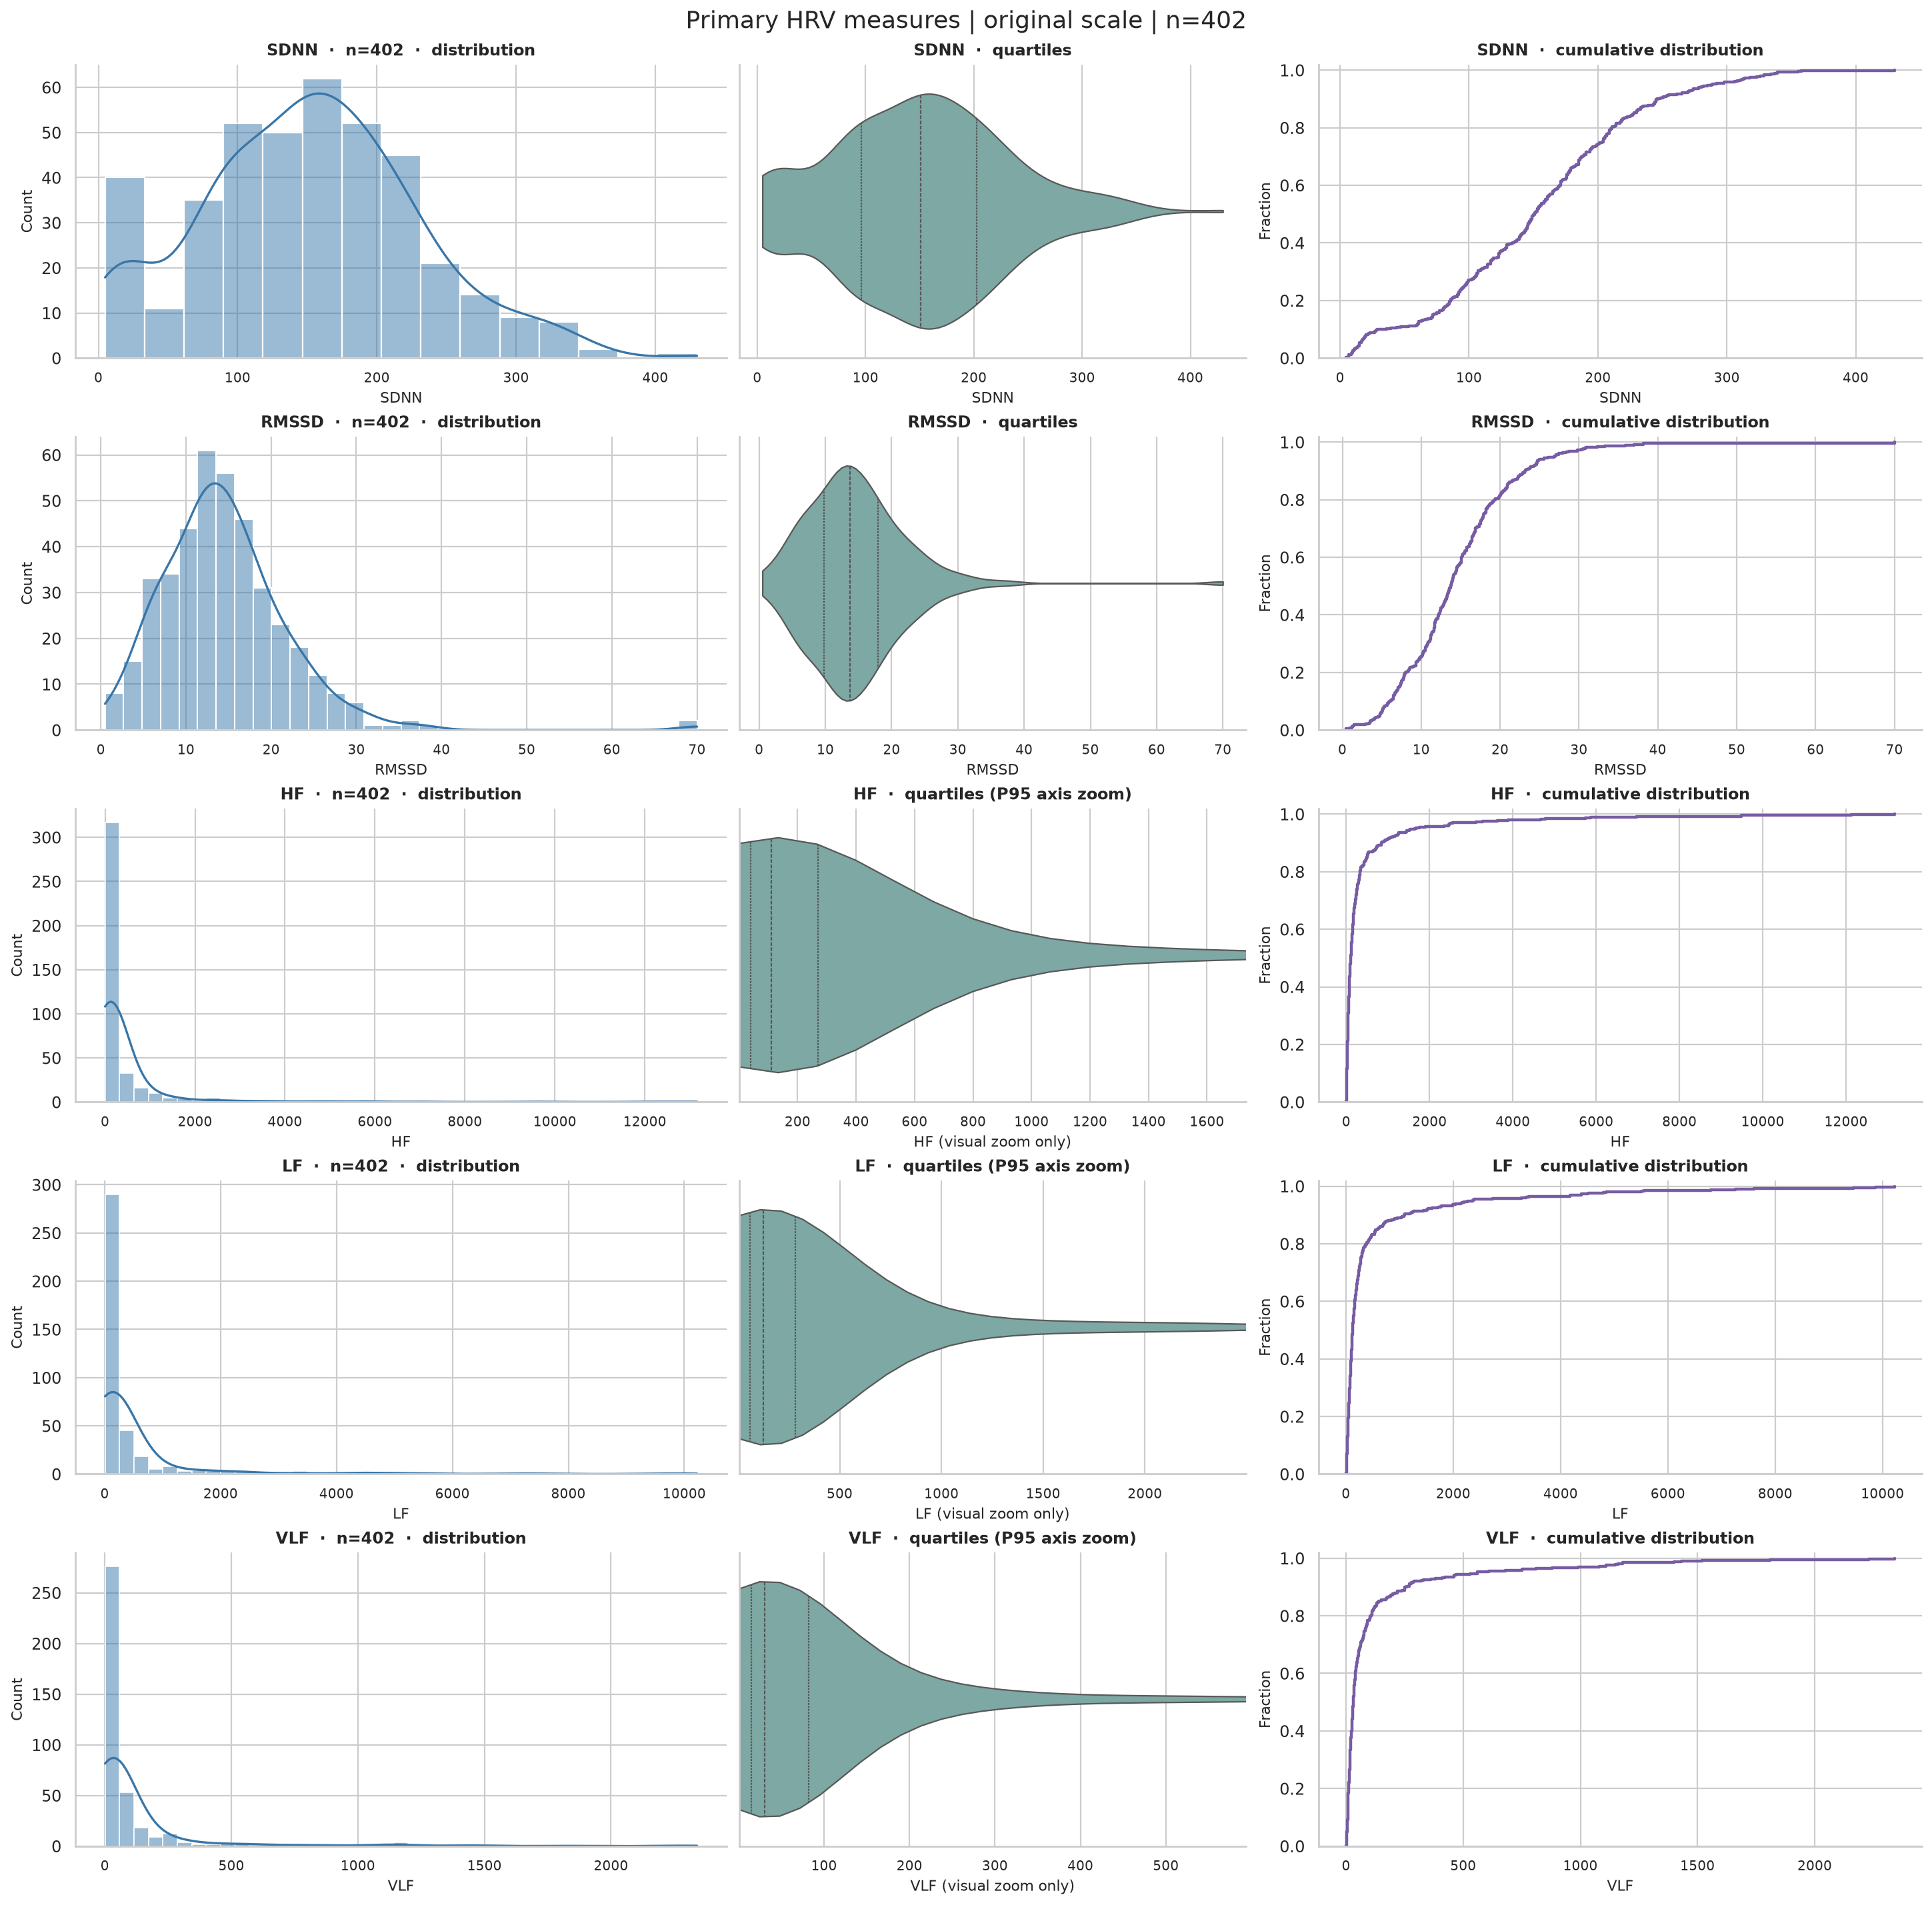

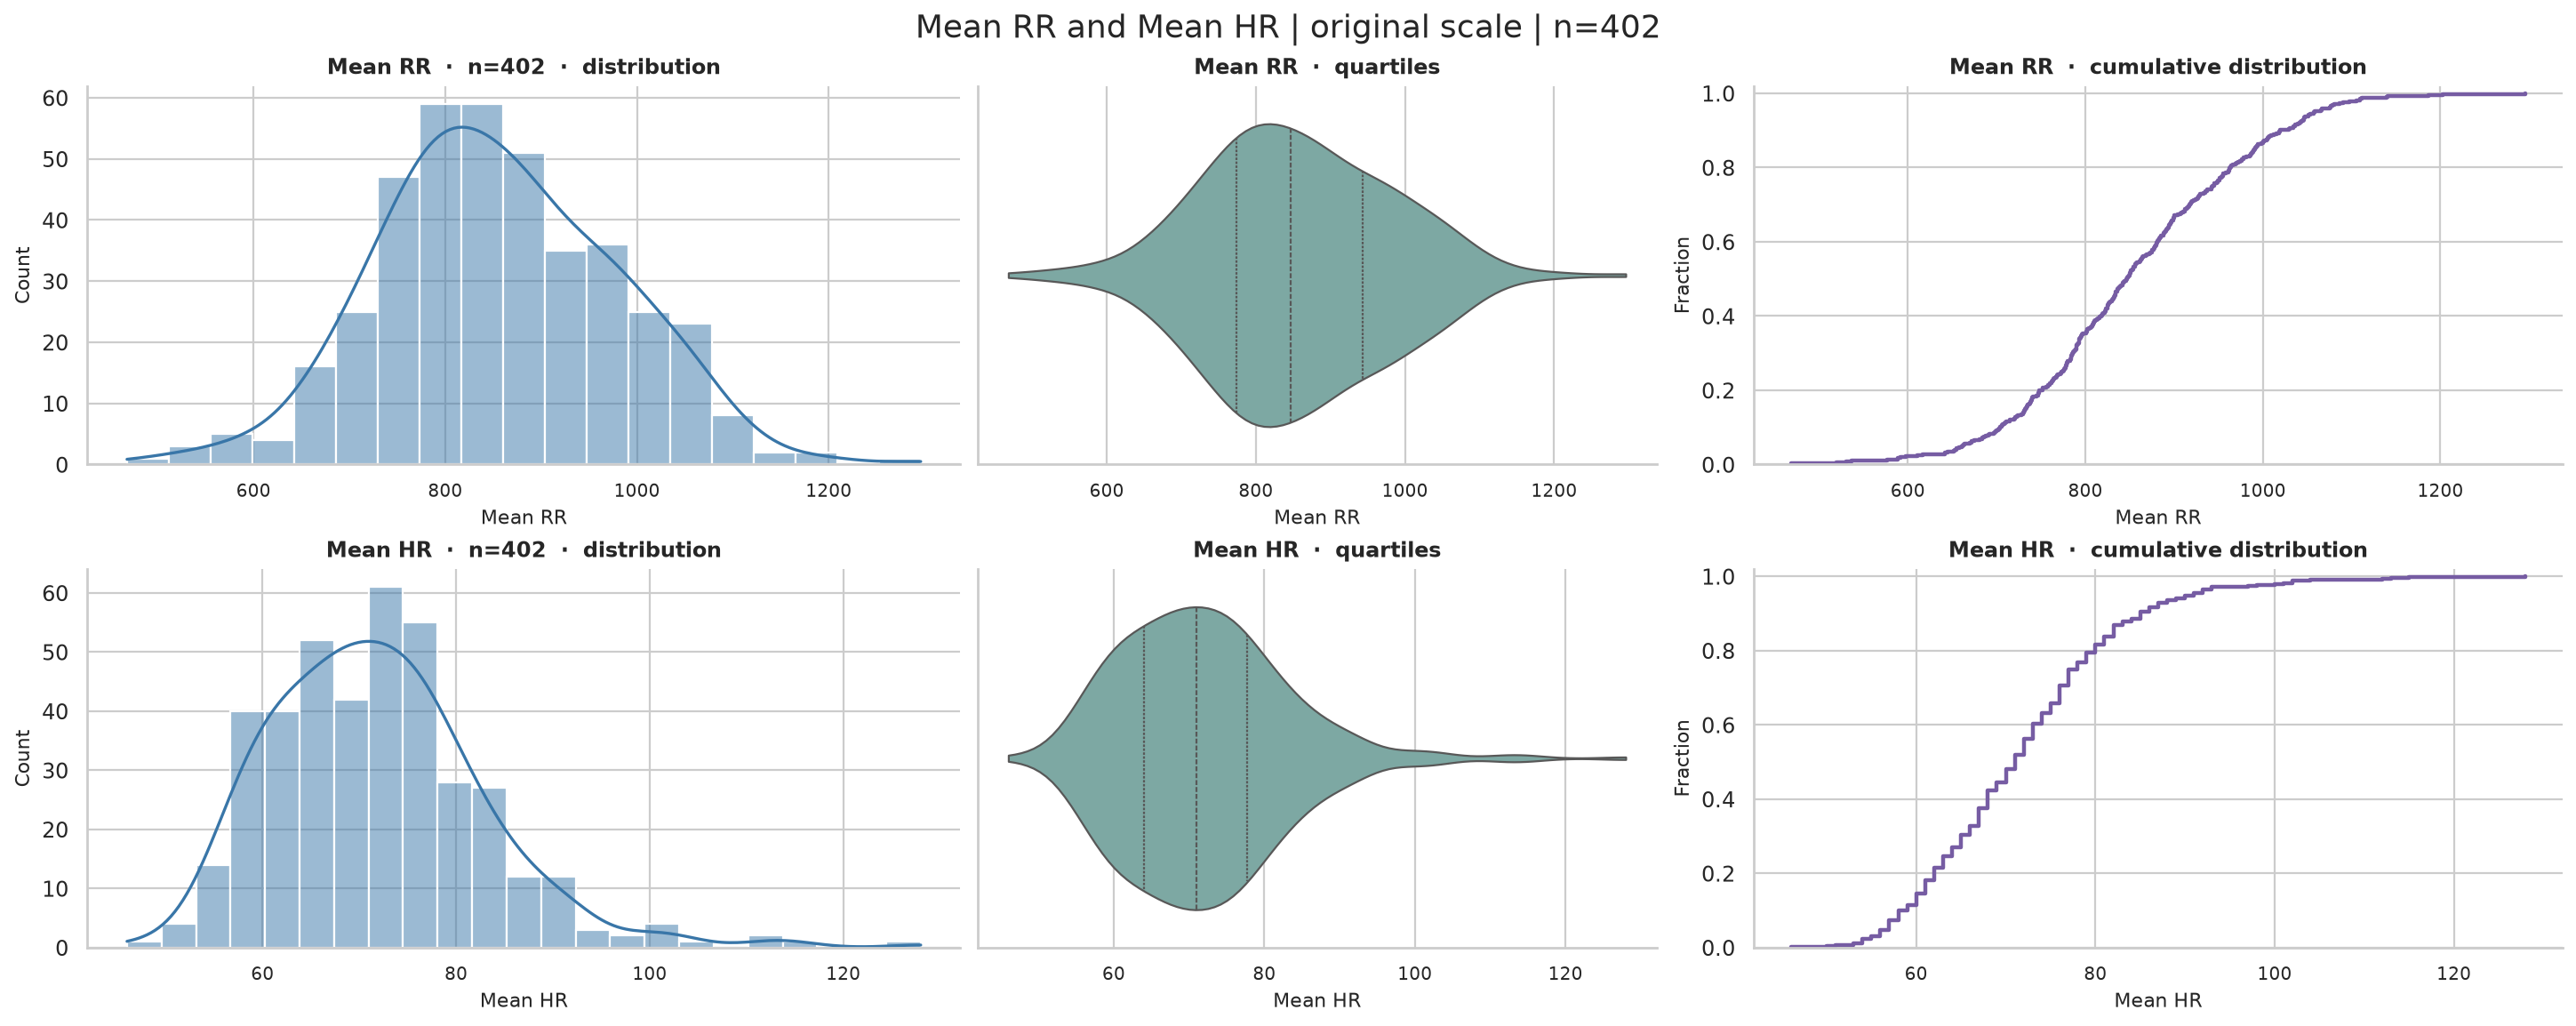

Two original-scale multipanel sheets generated; no per-variable figure exports.


In [3]:
def distribution_profile_panel(columns, filename, heading):
    fig, axes = plt.subplots(
        len(columns), 3,
        figsize=(18.0, 3.55 * len(columns)),
        gridspec_kw={'width_ratios': [1.35, 1.05, 1.25]},
        constrained_layout=True,
        squeeze=False,
    )
    for i, column in enumerate(columns):
        vals = source_df[column].dropna().astype(float)
        n = len(vals)
        kde = n >= 5 and vals.nunique() >= 3
        ax_hist, ax_violin, ax_ecdf = axes[i]
        if n:
            sns.histplot(x=vals, bins='auto', kde=kde, ax=ax_hist, color='#3976A8')
            if vals.nunique() >= 2:
                sns.violinplot(x=vals, ax=ax_violin, color='#76AFA9', inner='quart', cut=0,
                               linewidth=1)
            else:
                sns.stripplot(x=vals, ax=ax_violin, color='#76AFA9')
            sns.ecdfplot(x=vals, ax=ax_ecdf, color='#765CA3', linewidth=2)
        ax_hist.set(title=f'{label(column)}  ·  n={n}  ·  distribution',
                    xlabel=label(column), ylabel='Count')
        # For extremely long right tails, a clearly labeled P95 axis zoom reveals
        # the central distribution; histograms and ECDFs still display all records.
        p95 = vals.quantile(0.95) if n else np.nan
        zoom_violin = bool(n and np.isfinite(p95) and p95 > 0 and vals.max() > 3 * p95)
        if zoom_violin:
            ax_violin.set_xlim(left=max(0.0, float(vals.min())), right=float(p95) * 1.06)
        ax_violin.set(title=f'{label(column)}  ·  quartiles' + (' (P95 axis zoom)' if zoom_violin else ''),
                      xlabel=label(column) + (' (visual zoom only)' if zoom_violin else ''),
                      ylabel='', yticks=[])
        ax_ecdf.set(title=f'{label(column)}  ·  cumulative distribution',
                    xlabel=label(column), ylabel='Fraction', ylim=(0, 1.02))
        for ax in (ax_hist, ax_violin, ax_ecdf):
            ax.tick_params(axis='x', labelsize=9)
            sns.despine(ax=ax)
    fig.suptitle(heading, fontsize=16)
    return save_figure(fig, filename, 'distribution_profiles',
                       f'{len(columns)} variables × 3 views: histogram/KDE, violin/quartiles, ECDF')

primary_profile_path = distribution_profile_panel(
    MAIN_HRV_COLS, '01_primary_hrv_distribution_profiles.png',
    f'Primary HRV measures | original scale | n={N_RECORDS}'
)
cardiac_profile_path = distribution_profile_panel(
    CARDIAC_COLS, '02_cardiac_interval_rate_profiles.png',
    f'Mean RR and Mean HR | original scale | n={N_RECORDS}'
)
show_panel(primary_profile_path)
show_panel(cardiac_profile_path)
print('Two original-scale multipanel sheets generated; no per-variable figure exports.')


## 4. Alternative visualization scales and distribution diagnostics

One **7-row × 2-column** sheet compares the original and `log1p` histograms side by side where data are nonnegative. The log view is for visualization **only**; summary statistics continue to use original values. Records with negative measurements would have a labeled unavailable panel and would remain unaltered.

An optional **2 × 4 Q–Q grid** shows deviations from a normal reference line. This is visual characterization, **not** a normality test or criterion for excluding observations.


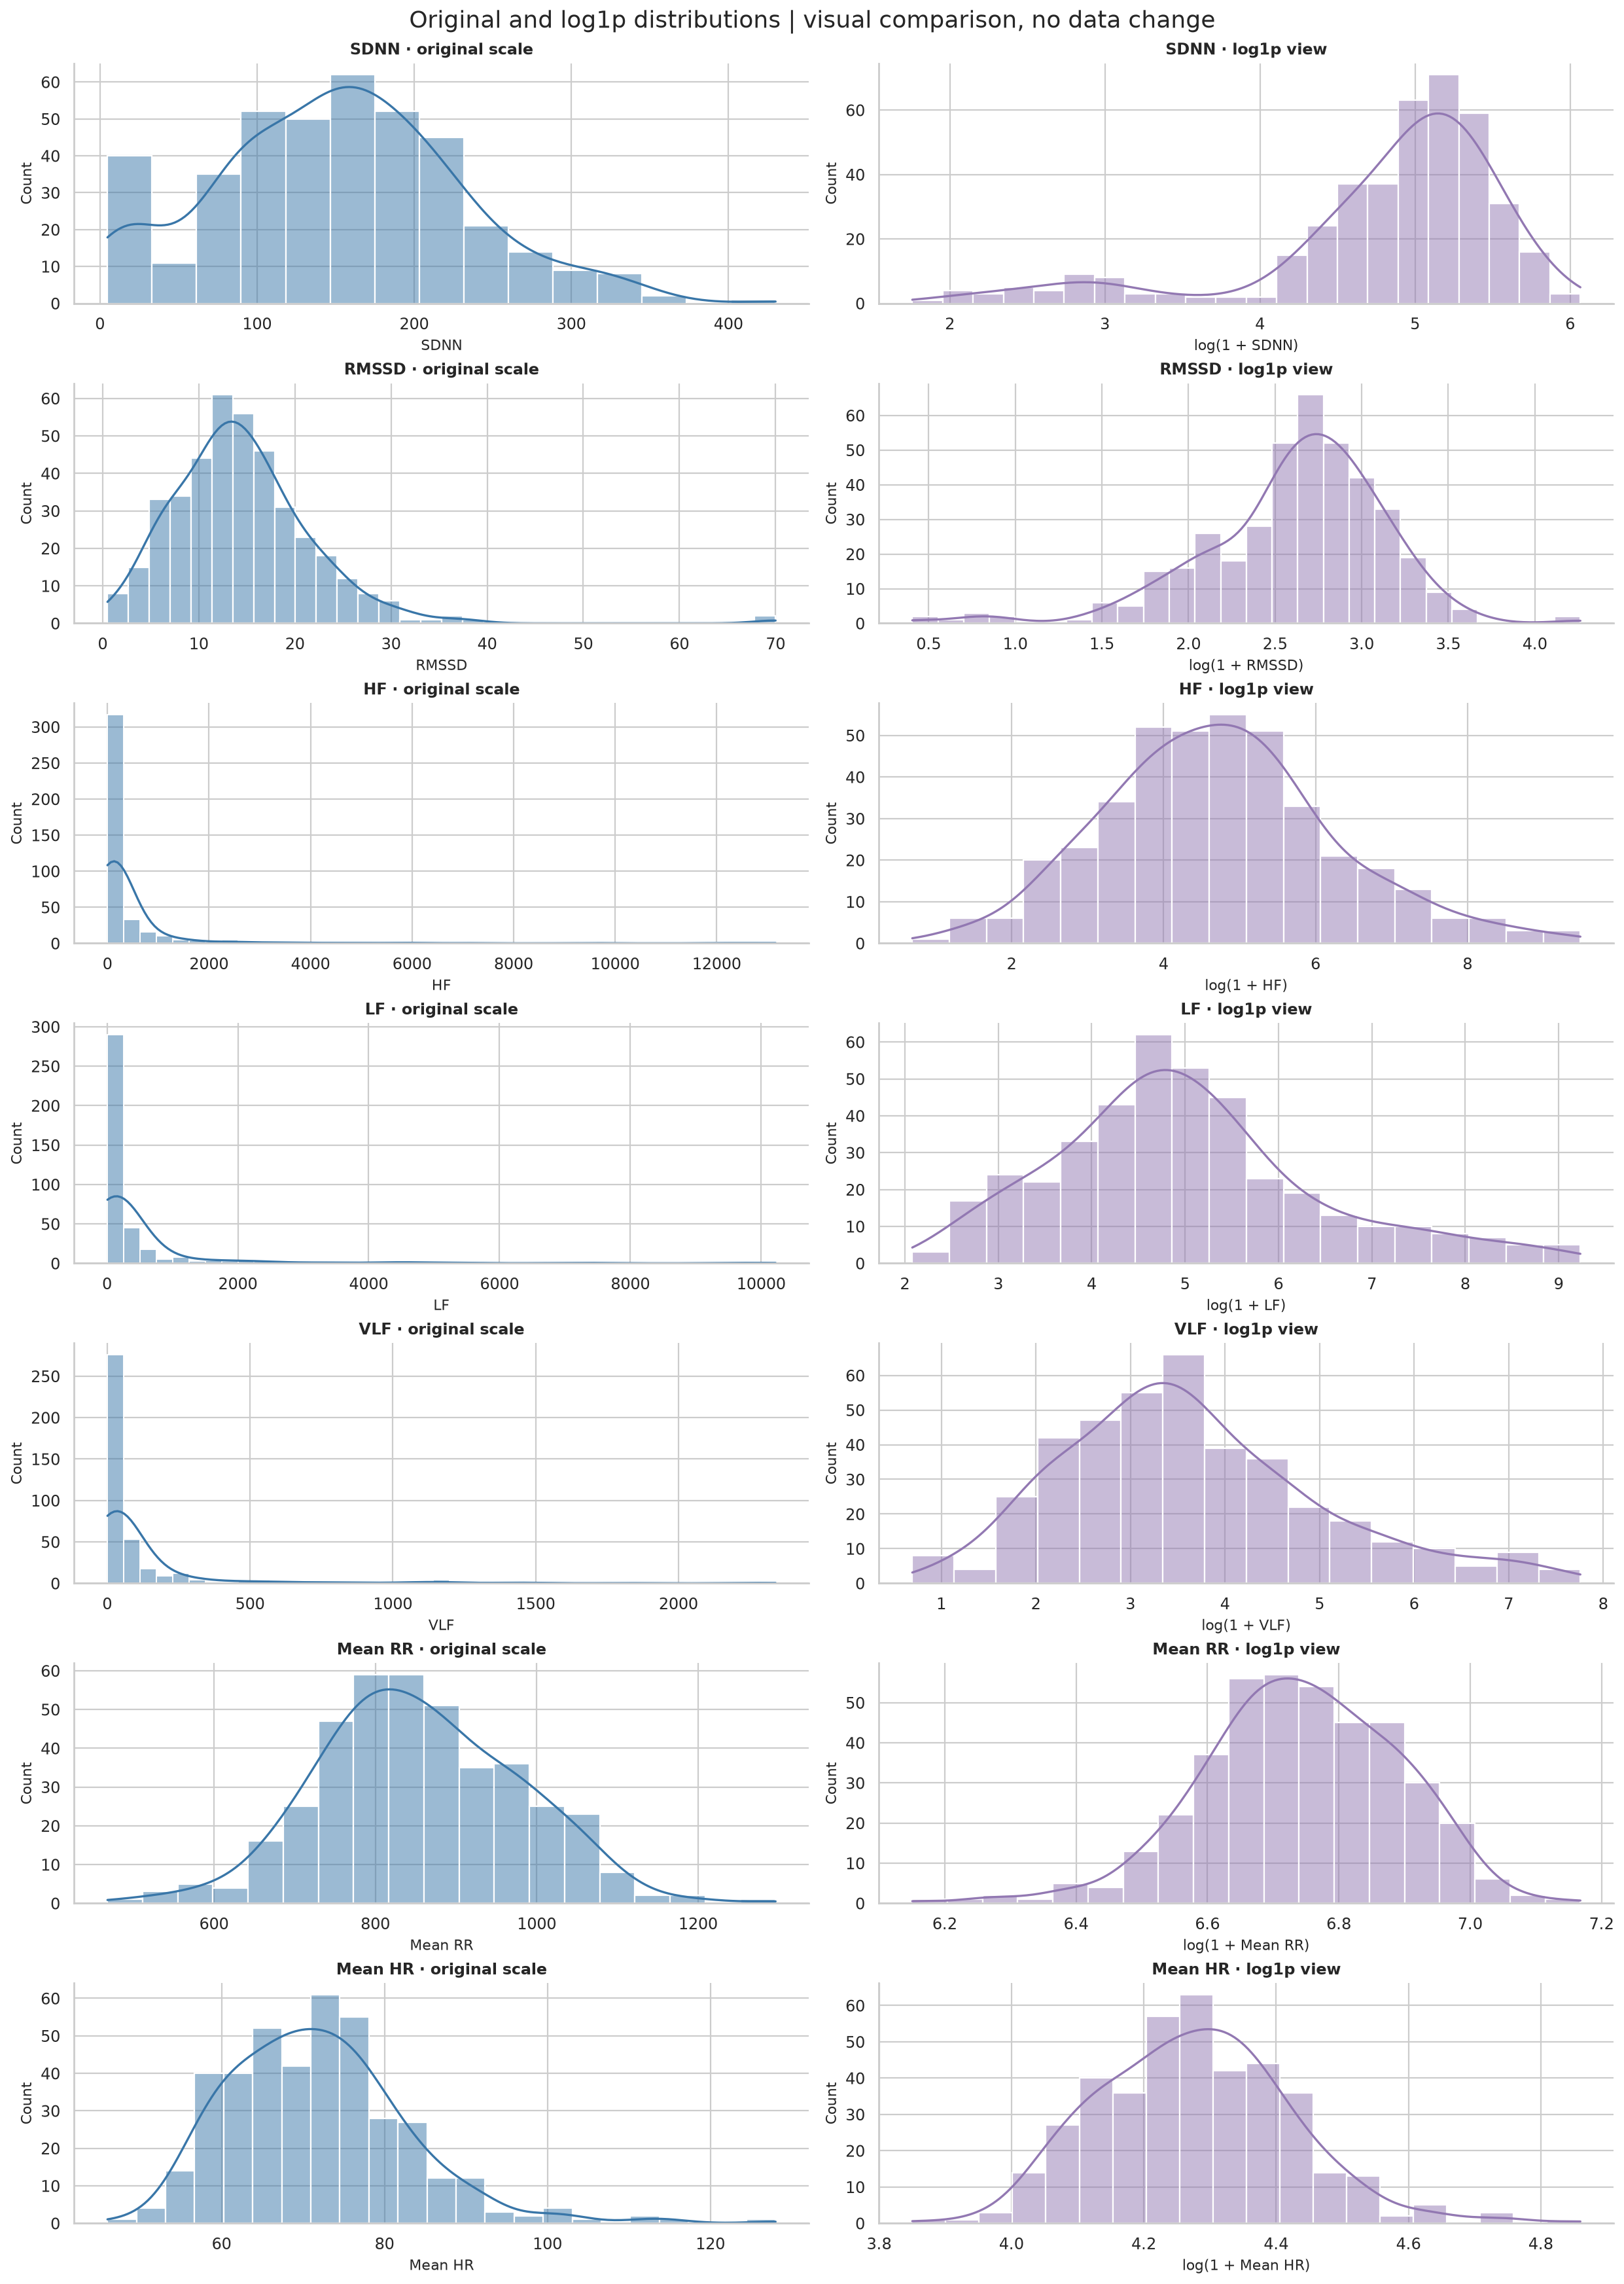

,variable,view,reason
0,t2m_pre_sdnn,log1p,all observed values non-negative
1,t2m_pre_rmssd,log1p,all observed values non-negative
2,t2m_pre_hf,log1p,all observed values non-negative
3,t2m_pre_lf,log1p,all observed values non-negative
4,t2m_pre_vlf,log1p,all observed values non-negative
5,t2m_pre_mean_rr,log1p,all observed values non-negative
6,t2m_pre_mean_hr,log1p,all observed values non-negative


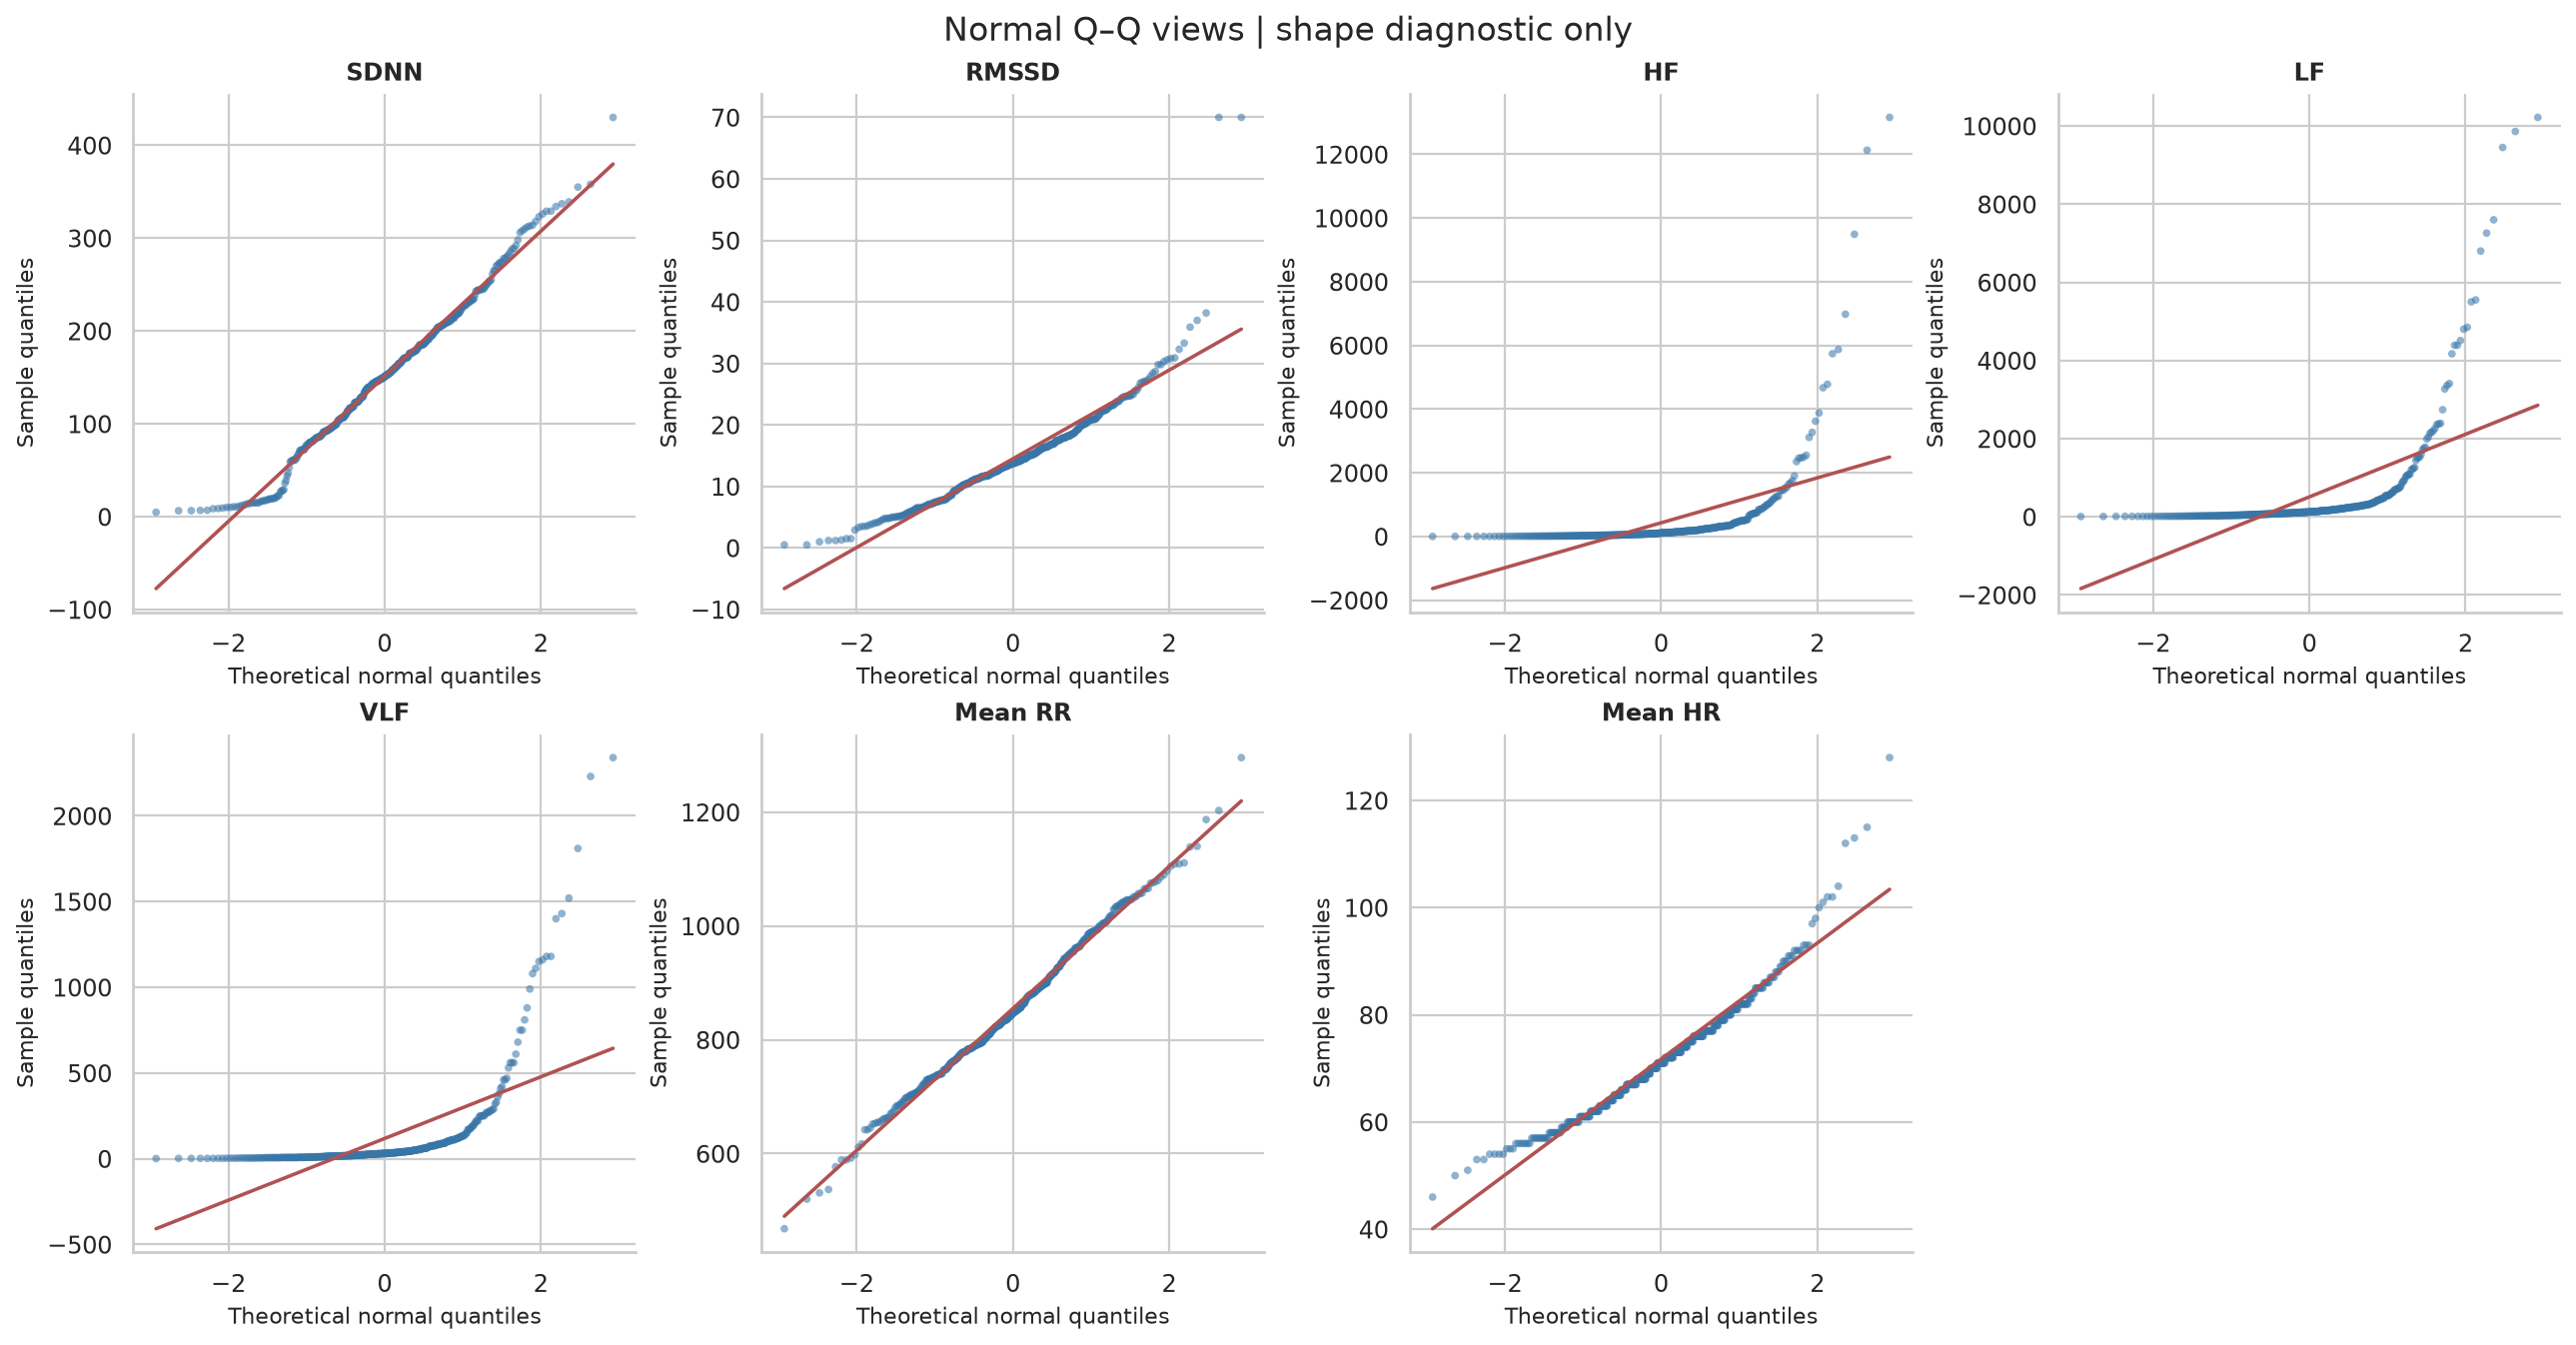

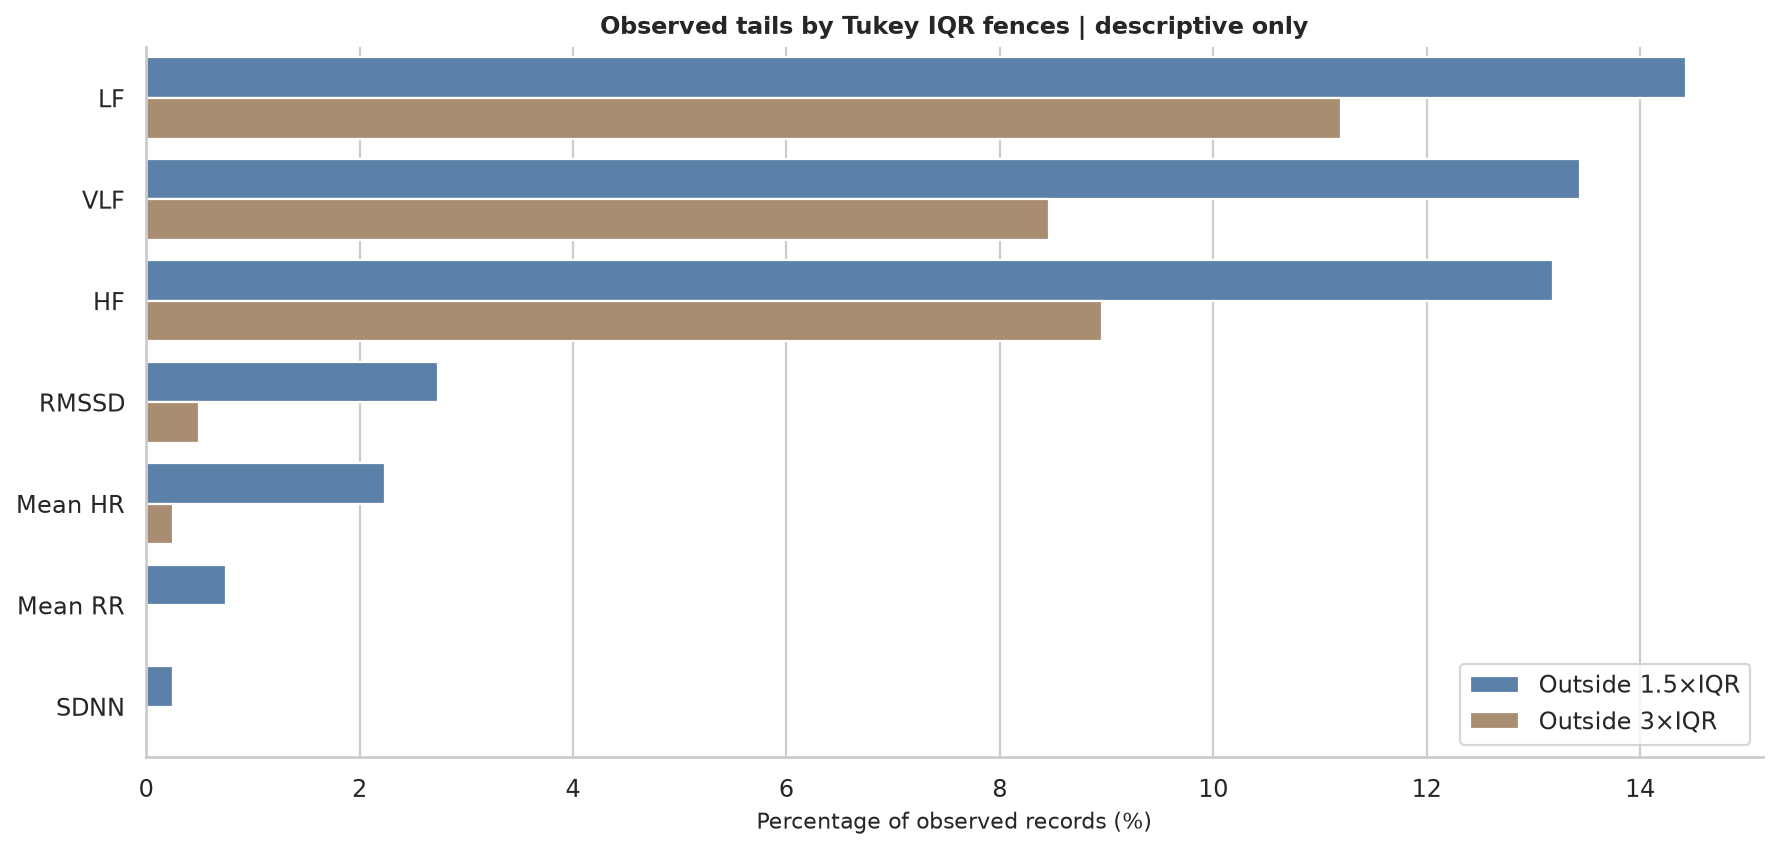

In [4]:
transformation_records = []
fig, axes = plt.subplots(len(HRV_COLS), 2, figsize=(15.4, 3.1 * len(HRV_COLS)),
                         constrained_layout=True, squeeze=False)
for i, column in enumerate(HRV_COLS):
    vals = source_df[column].dropna().astype(float)
    ax_original, ax_log = axes[i]
    use_kde = len(vals) >= 5 and vals.nunique() >= 3
    sns.histplot(x=vals, bins='auto', kde=use_kde, ax=ax_original, color='#3976A8')
    ax_original.set(title=f'{label(column)} · original scale', xlabel=label(column), ylabel='Count')
    if vals.empty or (vals < 0).any():
        transformation_records.append({'variable': column, 'view': 'not generated',
                                       'reason': 'missing or negative values'})
        ax_log.text(0.5, 0.5, 'log1p view unavailable', ha='center', va='center',
                    transform=ax_log.transAxes)
        ax_log.set_axis_off()
    else:
        logvals = np.log1p(vals)
        transformation_records.append({'variable': column, 'view': 'log1p',
                                       'reason': 'all observed values non-negative'})
        sns.histplot(x=logvals, bins='auto', kde=use_kde, ax=ax_log, color='#9278B2')
        ax_log.set(title=f'{label(column)} · log1p view',
                   xlabel=f'log(1 + {label(column)})', ylabel='Count')
    sns.despine(ax=ax_original)
    sns.despine(ax=ax_log)
fig.suptitle('Original and log1p distributions | visual comparison, no data change', fontsize=16)
scale_path = save_figure(
    fig, '03_original_vs_log1p_distributions.png', 'scale_comparison',
    'Seven HRV/interval measures, original and visualization-only log1p histograms'
)
show_panel(scale_path)

transformation_log = pd.DataFrame(transformation_records)
transformation_log.to_csv(TABLES_DIR / 'hrv_visualization_scales.csv', index=False)
display(transformation_log)

if MAKE_QQ_PANEL:
    fig, axes = plt.subplots(2, 4, figsize=(16, 8.3), constrained_layout=True)
    for ax, column in zip(axes.flat, HRV_COLS):
        vals = source_df[column].dropna().astype(float)
        if len(vals) >= 3 and vals.nunique() >= 2:
            (osm, osr), (slope, intercept, r) = stats.probplot(vals, dist='norm', fit=True)
            ax.scatter(osm, osr, s=12, alpha=0.56, color='#3976A8', edgecolor='none')
            ax.plot(osm, slope * osm + intercept, color='#B05253', linewidth=1.6)
            ax.set(title=label(column), xlabel='Theoretical normal quantiles', ylabel='Sample quantiles')
        else:
            ax.text(0.5, 0.5, 'Q–Q unavailable', ha='center', va='center', transform=ax.transAxes)
            ax.set(title=label(column))
        sns.despine(ax=ax)
    for ax in list(axes.flat)[len(HRV_COLS):]:
        ax.axis('off')
    fig.suptitle('Normal Q–Q views | shape diagnostic only', fontsize=15)
    qq_path = save_figure(fig, '04_normal_qq_grid.png', 'qq_panel',
                          'Normal-reference Q–Q plots for the seven observed measures')
    show_panel(qq_path)

# One concise overview of descriptive distribution tails. These are NOT invalidity labels.
tail_frame = summary[['label', 'pct_outside_1_5_iqr', 'pct_outside_3_iqr']].melt(
    id_vars='label', var_name='fence', value_name='percentage')
tail_frame['fence'] = tail_frame['fence'].map({
    'pct_outside_1_5_iqr': 'Outside 1.5×IQR', 'pct_outside_3_iqr': 'Outside 3×IQR'
})
fig, ax = plt.subplots(figsize=(11, 5.2), constrained_layout=True)
sns.barplot(data=tail_frame, x='percentage', y='label', hue='fence',
            order=summary.sort_values('pct_outside_1_5_iqr', ascending=False)['label'],
            ax=ax, palette=['#4E81B6', '#B28D67'])
ax.set(title='Observed tails by Tukey IQR fences | descriptive only',
       xlabel='Percentage of observed records (%)', ylabel='')
ax.legend(title='', loc='lower right')
sns.despine(ax=ax)
tail_path = save_figure(fig, '05_iqr_tail_summary.png', 'tail_overview',
                        'Side-by-side percentages outside 1.5× and 3× IQR fences')
show_panel(tail_path, 850)


## 5. Descriptive relationships among HRV and cardiac variables

Spearman coefficients and paired sample sizes are reported without hypothesis tests or p-values. All available original-scale values contribute to the correlation matrix.

The figure set is deliberately compact: **one correlation heatmap**, **one five-indicator log1p pairplot**, **one focused four-pair comparison sheet**, and an optional **5 × 2 HRV-versus-RR/HR sheet**. No individual scatterplot PNGs are exported. `log1p` scatter views are explicitly labeled and never change the exported data.


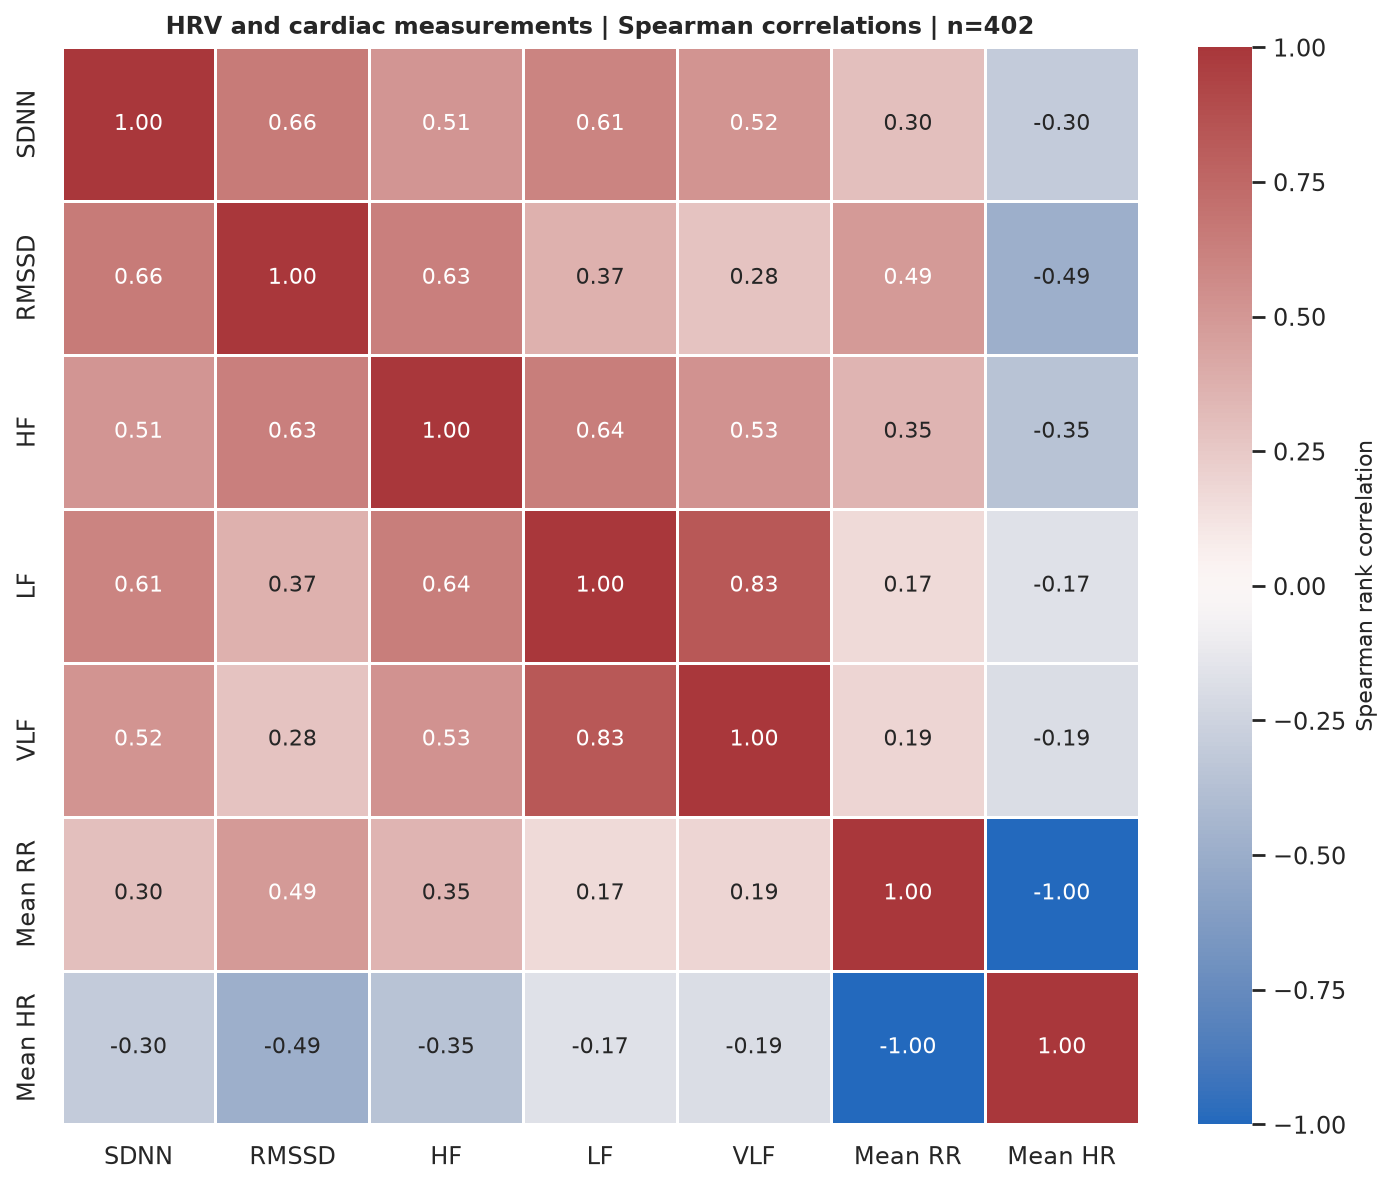

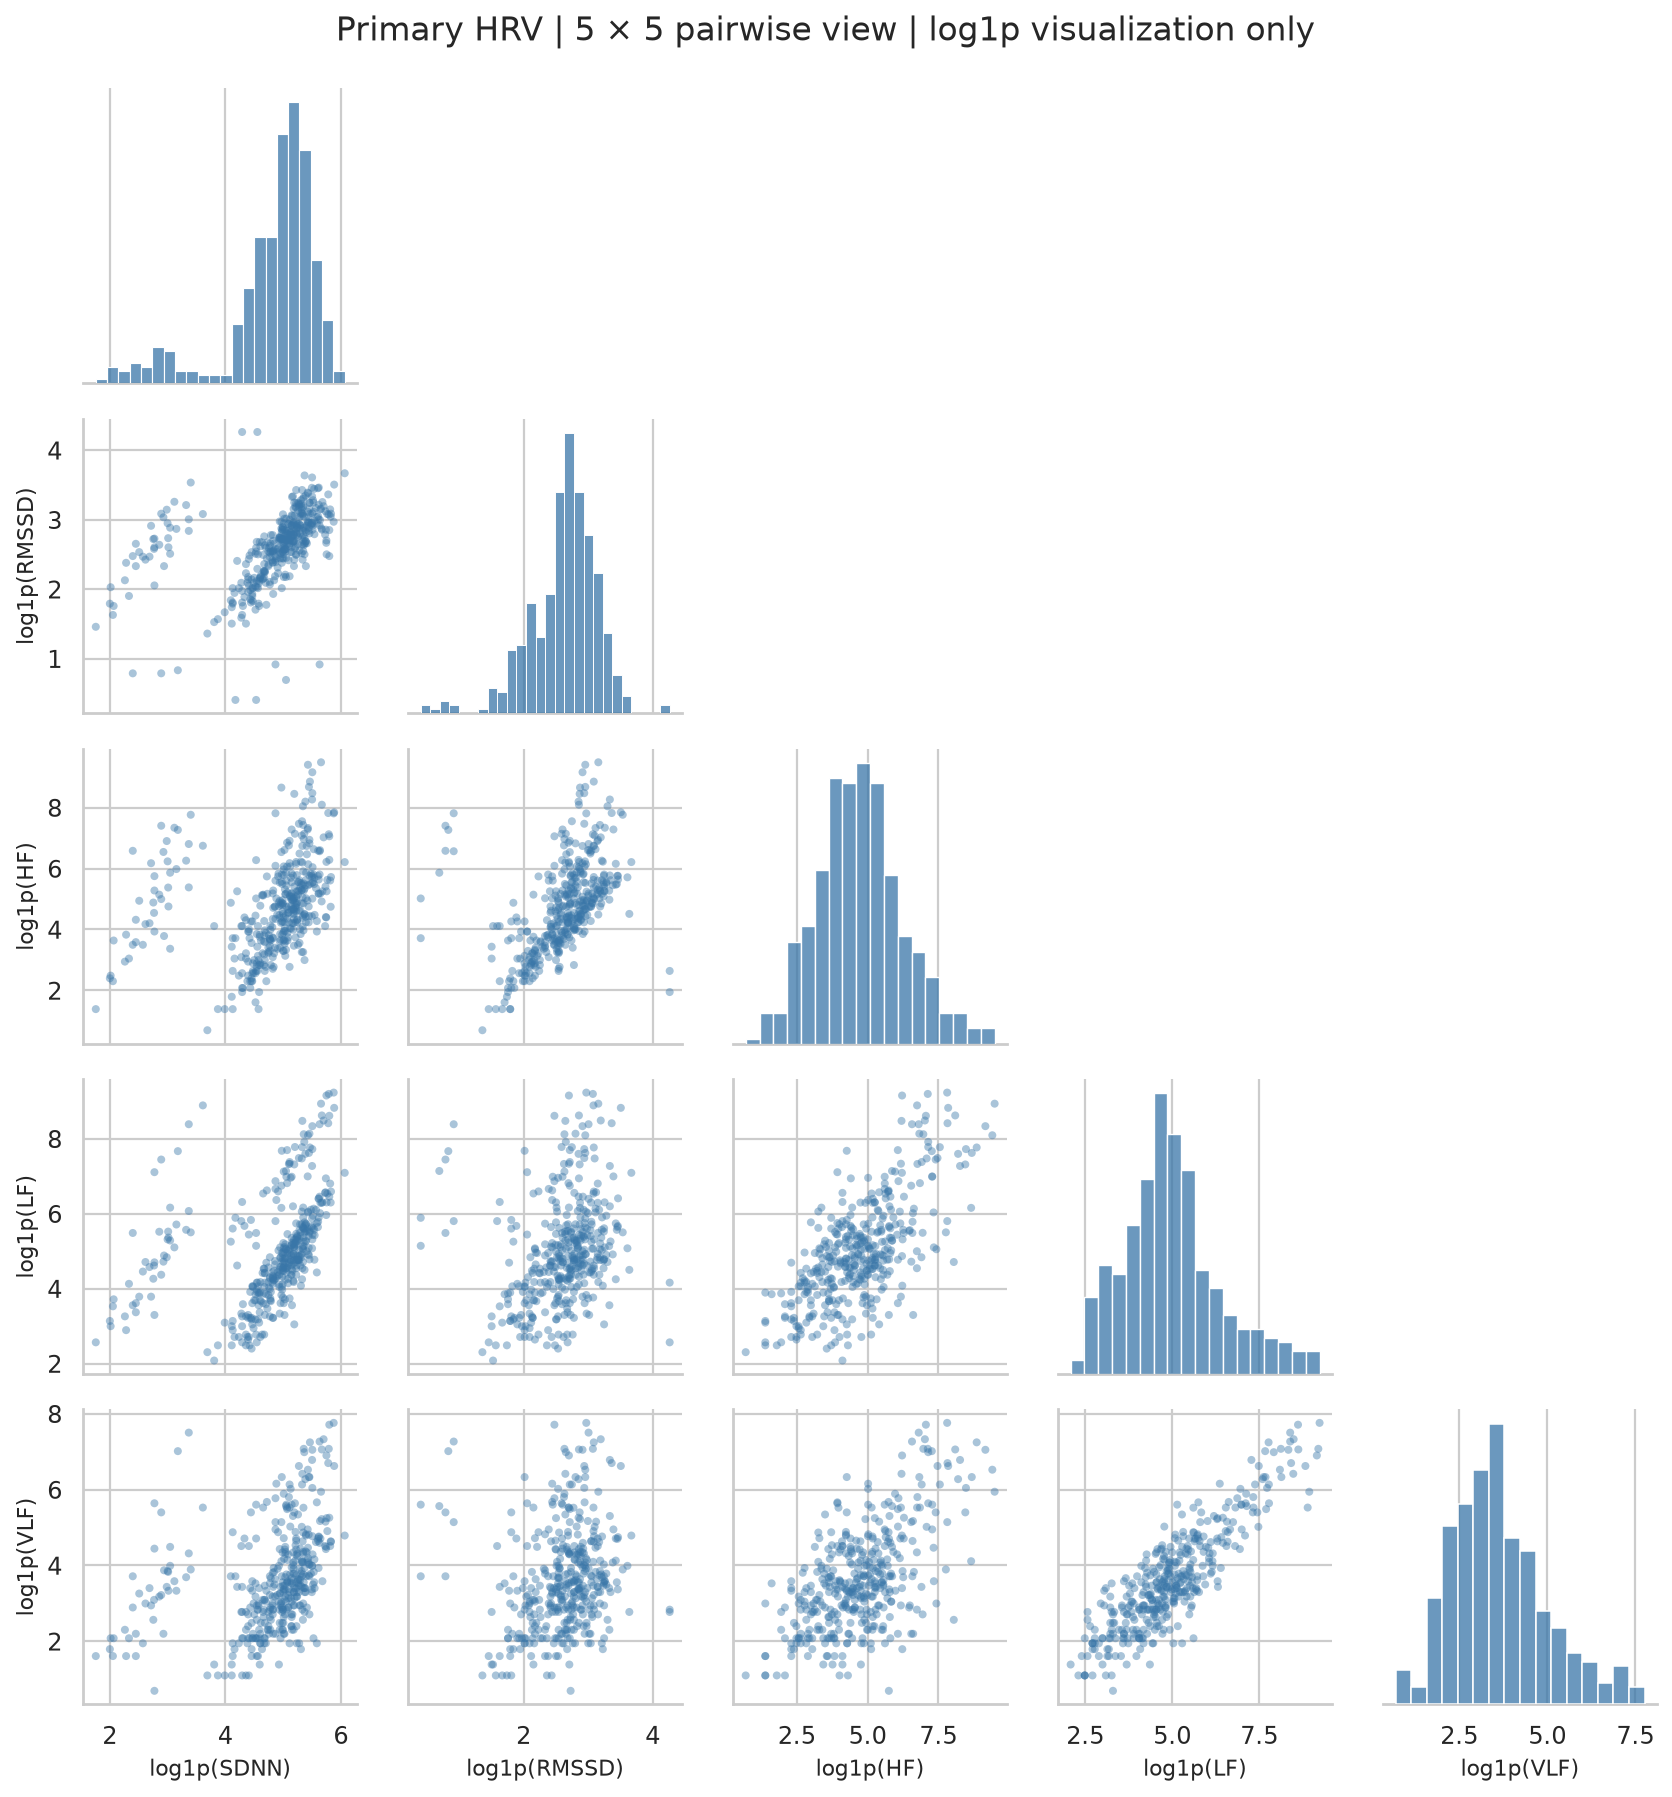

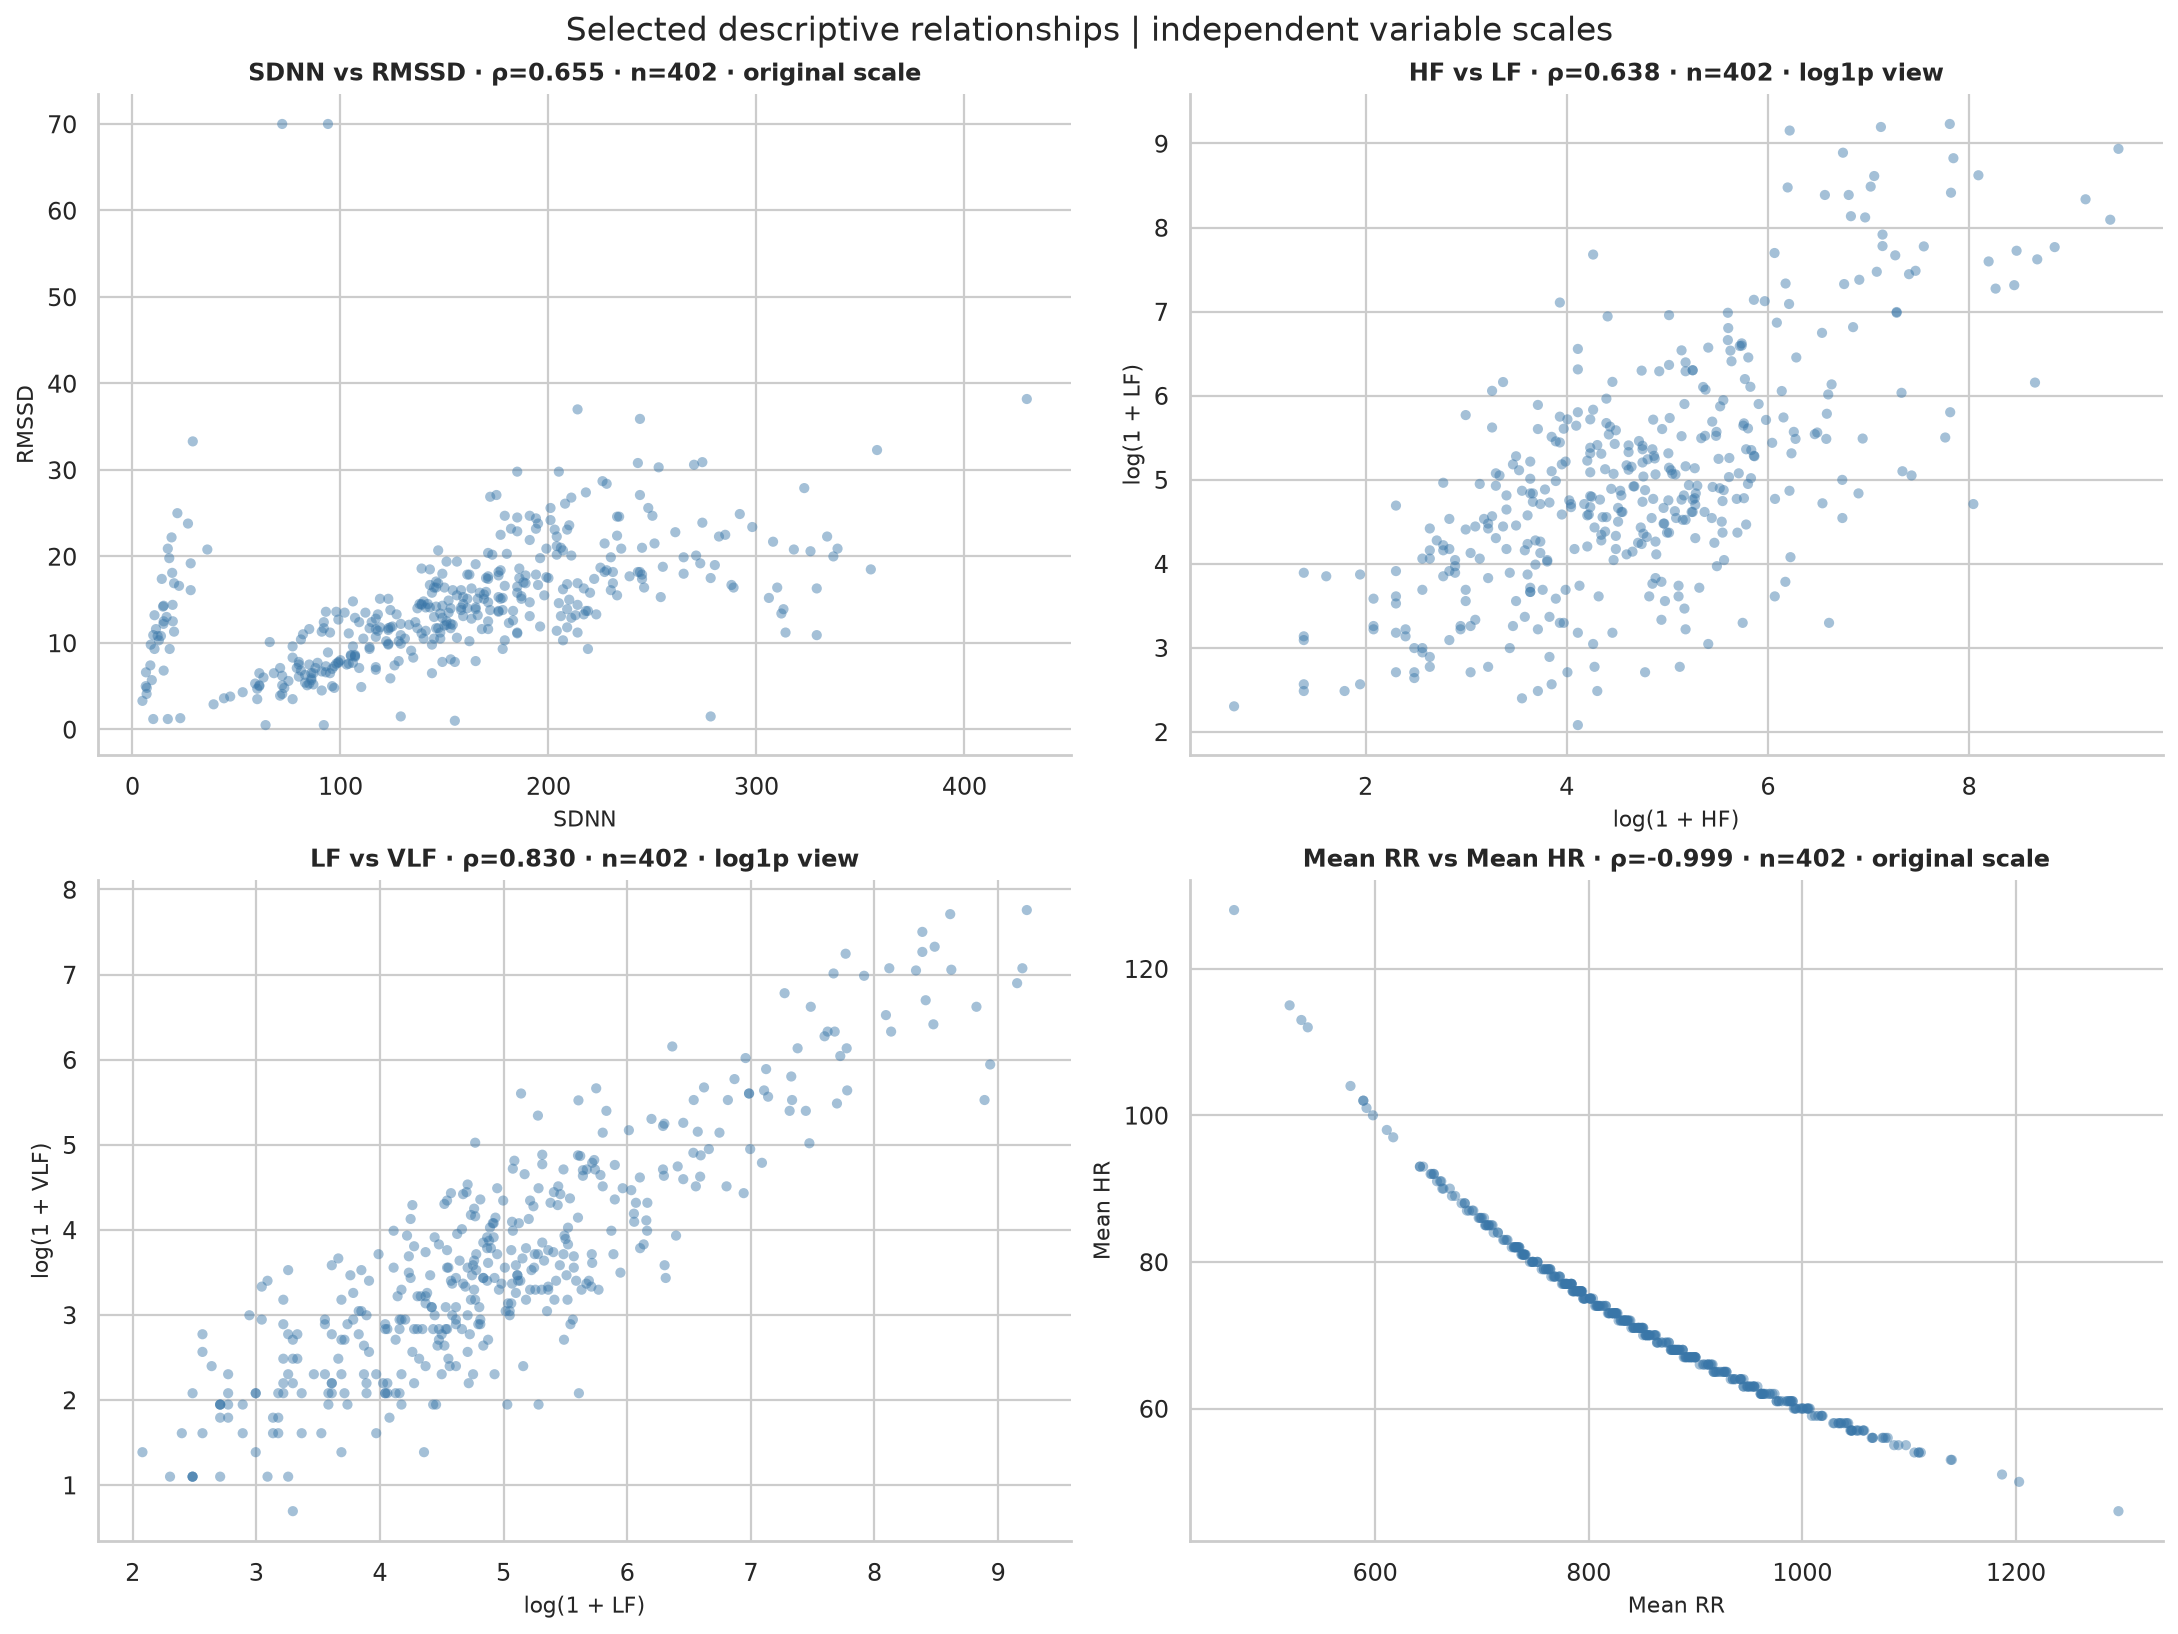

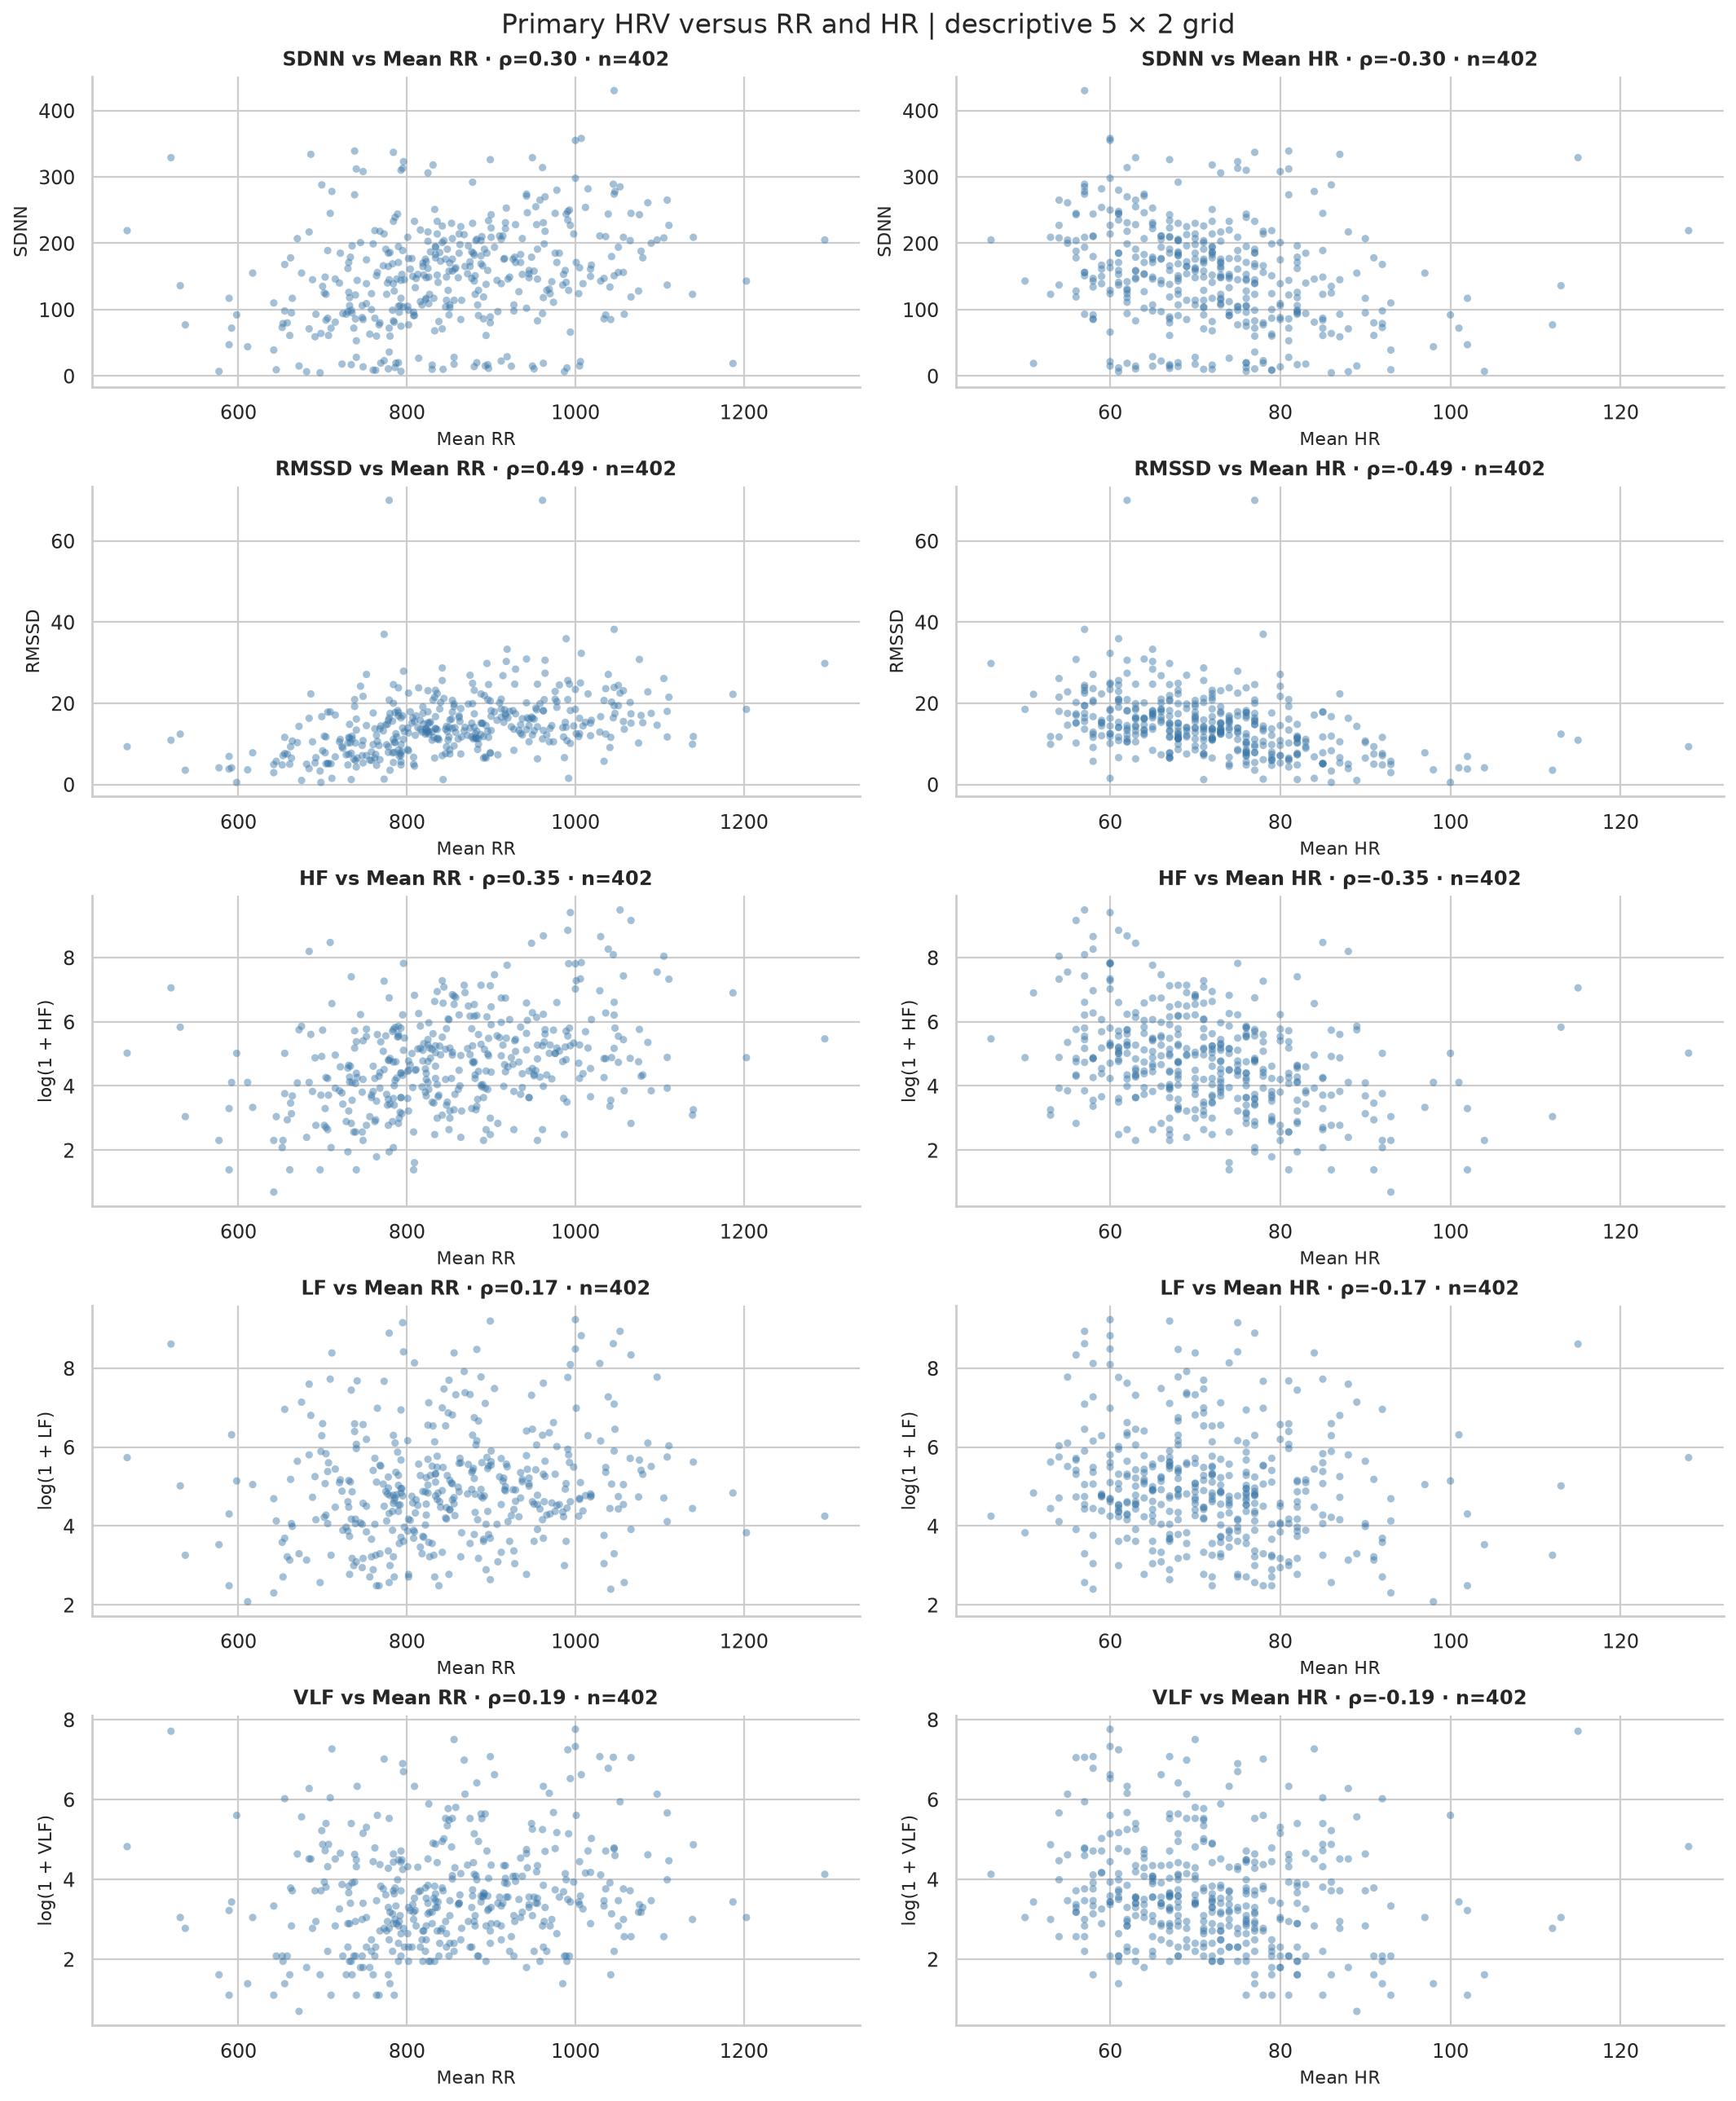

,variable_a,variable_b,n_pair,spearman_rho,abs_rho
20,t2m_pre_mean_rr,t2m_pre_mean_hr,402,-0.999,0.999
15,t2m_pre_lf,t2m_pre_vlf,402,0.830,0.830
0,t2m_pre_sdnn,t2m_pre_rmssd,402,0.655,0.655
11,t2m_pre_hf,t2m_pre_lf,402,0.638,0.638
6,t2m_pre_rmssd,t2m_pre_hf,402,0.632,0.632
2,t2m_pre_sdnn,t2m_pre_lf,402,0.608,0.608
12,t2m_pre_hf,t2m_pre_vlf,402,0.528,0.528
3,t2m_pre_sdnn,t2m_pre_vlf,402,0.520,0.520
1,t2m_pre_sdnn,t2m_pre_hf,402,0.514,0.514
10,t2m_pre_rmssd,t2m_pre_mean_hr,402,-0.491,0.491


Descriptive relationship panels complete; no inferential tests.


In [5]:
pair_rows = []
for col_a, col_b in combinations(HRV_COLS, 2):
    pair = source_df[[col_a, col_b]].dropna()
    if len(pair) > 1 and pair[col_a].nunique() > 1 and pair[col_b].nunique() > 1:
        rho = float(pair[col_a].corr(pair[col_b], method='spearman'))
    else:
        rho = np.nan
    pair_rows.append({'variable_a': col_a, 'variable_b': col_b,
                      'n_pair': len(pair), 'spearman_rho': rho})

pairs = pd.DataFrame(pair_rows)
pairs.to_csv(TABLES_DIR / 'hrv_spearman_pairs.csv', index=False)
rho_matrix = source_df[HRV_COLS].corr(method='spearman')
rho_matrix.to_csv(TABLES_DIR / 'hrv_spearman_matrix.csv', index=True)

fig, ax = plt.subplots(figsize=(9.0, 7.3), constrained_layout=True)
pretty_rho = rho_matrix.copy()
pretty_rho.index = [label(col) for col in pretty_rho.index]
pretty_rho.columns = [label(col) for col in pretty_rho.columns]
sns.heatmap(pretty_rho, ax=ax, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1,
            center=0, square=True, linewidths=0.5,
            cbar_kws={'label': 'Spearman rank correlation'})
ax.set(title=f'HRV and cardiac measurements | Spearman correlations | n={N_RECORDS}')
heatmap_path = save_figure(fig, '06_hrv_spearman_heatmap.png', 'spearman_heatmap',
                           'Seven-variable Spearman coefficient matrix')
show_panel(heatmap_path, 820)

if MAKE_HRV_PAIRPLOT:
    if all((source_df[col].dropna() >= 0).all() for col in MAIN_HRV_COLS):
        pairplot_data = pd.DataFrame({f'log1p({label(col)})': np.log1p(source_df[col]) for col in MAIN_HRV_COLS})
        grid = sns.PairGrid(pairplot_data, corner=True, height=2.2, diag_sharey=False)
        grid.map_diag(sns.histplot, bins='auto', color='#3976A8')
        grid.map_lower(sns.scatterplot, alpha=0.43, s=13,
                       edgecolor='none', color='#3976A8')
        grid.figure.suptitle('Primary HRV | 5 × 5 pairwise view | log1p visualization only',
                             y=1.02, fontsize=15)
        pairplot_path = save_figure(
            grid.figure, '07_primary_hrv_log1p_pairplot.png', 'pairplot_log1p',
            'Five main HRV measures: diagonal distributions and all 10 unique scatterplots'
        )
        show_panel(pairplot_path, 950)
    else:
        print('Primary HRV log1p pairplot skipped because negative values are present.')

selected_pairs = [
    ('t2m_pre_sdnn', 't2m_pre_rmssd'),
    ('t2m_pre_hf', 't2m_pre_lf'),
    ('t2m_pre_lf', 't2m_pre_vlf'),
    ('t2m_pre_mean_rr', 't2m_pre_mean_hr'),
]
fig, axes = plt.subplots(2, 2, figsize=(13.5, 10.1), constrained_layout=True)
for ax, (xcol, ycol) in zip(axes.flat, selected_pairs):
    pair = source_df[[xcol, ycol]].dropna()
    positive_skew_band = (xcol in ['t2m_pre_hf', 't2m_pre_lf', 't2m_pre_vlf'] and
                          ycol in ['t2m_pre_hf', 't2m_pre_lf', 't2m_pre_vlf'])
    x_vals = np.log1p(pair[xcol]) if positive_skew_band else pair[xcol]
    y_vals = np.log1p(pair[ycol]) if positive_skew_band else pair[ycol]
    sns.scatterplot(x=x_vals, y=y_vals, ax=ax, alpha=0.46, s=21,
                    edgecolor='none', color='#3976A8')
    rho = pair[xcol].corr(pair[ycol], method='spearman')
    rho_txt = f'{rho:.3f}' if np.isfinite(rho) else 'NA'
    scale_note = ' · log1p view' if positive_skew_band else ' · original scale'
    ax.set(title=f'{label(xcol)} vs {label(ycol)} · ρ={rho_txt} · n={len(pair)}{scale_note}',
           xlabel=f'log(1 + {label(xcol)})' if positive_skew_band else label(xcol),
           ylabel=f'log(1 + {label(ycol)})' if positive_skew_band else label(ycol))
    sns.despine(ax=ax)
fig.suptitle('Selected descriptive relationships | independent variable scales', fontsize=15)
selected_path = save_figure(fig, '08_selected_hrv_relationships.png', 'selected_scatter_grid',
                            'Four key pairs: SDNN–RMSSD, HF–LF, LF–VLF and mean RR–mean HR')
show_panel(selected_path)

if MAKE_CROSS_DOMAIN_PANEL:
    fig, axes = plt.subplots(len(MAIN_HRV_COLS), len(CARDIAC_COLS),
                             figsize=(13.2, 3.2 * len(MAIN_HRV_COLS)),
                             constrained_layout=True, squeeze=False)
    for i, hrv_col in enumerate(MAIN_HRV_COLS):
        for j, cardiac_col in enumerate(CARDIAC_COLS):
            ax = axes[i, j]
            pair = source_df[[cardiac_col, hrv_col]].dropna()
            # Log1p is a visualization-only choice for strongly right-skewed frequency bands.
            log_y = hrv_col in ('t2m_pre_hf', 't2m_pre_lf', 't2m_pre_vlf') and (pair[hrv_col] >= 0).all()
            yy = np.log1p(pair[hrv_col]) if log_y else pair[hrv_col]
            sns.scatterplot(x=pair[cardiac_col], y=yy, ax=ax, alpha=0.46, s=17,
                            edgecolor='none', color='#3976A8')
            rho = pair[hrv_col].corr(pair[cardiac_col], method='spearman')
            ax.set(title=f'{label(hrv_col)} vs {label(cardiac_col)} · ρ={rho:.2f} · n={len(pair)}',
                   xlabel=label(cardiac_col),
                   ylabel=f'log(1 + {label(hrv_col)})' if log_y else label(hrv_col))
            sns.despine(ax=ax)
    fig.suptitle('Primary HRV versus RR and HR | descriptive 5 × 2 grid', fontsize=15)
    cross_path = save_figure(fig, '09_primary_hrv_vs_cardiac_measures.png',
                             'hrv_cardiac_scatter_grid',
                             'Five main HRV measures crossed with mean RR and mean HR')
    show_panel(cross_path)

display(pairs.assign(abs_rho=pairs['spearman_rho'].abs()).sort_values('abs_rho', ascending=False).head(10).round(3))
print('Descriptive relationship panels complete; no inferential tests.')


## 6. Generate stage documentation and results report

The README records the **actual multipanel output design**, methods, and input checksum. The results Markdown describes the computed distributions and correlations and links the figure index. This stage never changes the source dataset.


In [6]:
def format_value(value, decimals=2):
    if pd.isna(value):
        return 'NA'
    if isinstance(value, (int, np.integer)):
        return str(value)
    return f'{float(value):.{decimals}f}'

def markdown_table(frame, columns, decimals=2):
    head = '| ' + ' | '.join(columns) + ' |'
    sep = '| ' + ' | '.join(['---'] * len(columns)) + ' |'
    body = []
    for _, row in frame[columns].iterrows():
        body.append('| ' + ' | '.join(format_value(row[col], decimals) if pd.api.types.is_number(row[col])
                                        else str(row[col]) for col in columns) + ' |')
    return '\n'.join([head, sep, *body])

figure_manifest = pd.DataFrame(figure_records)
assert figure_manifest['figure'].is_unique
assert len(figure_manifest) <= 9, 'Multipanel design unexpectedly generated too many figure files.'
figure_manifest.to_csv(TABLES_DIR / 'figure_manifest.csv', index=False)

readme = f'''# Data inspection — 05.01 HRV inspection

## Scope

Standalone descriptive inspection of the five primary HRV measurements (SDNN, RMSSD, HF, LF, VLF) and two complementary cardiac interval/rate measures (mean RR and mean HR). This is **not** a factor comparison or modeling stage.

## Input and provenance

- Source file: `outputs/dataset_final.csv`, generated by the accepted preprocessing workflow `01 → 01b → 02 → 03 → 04`.
- Dataset analyzed in this run: **{N_RECORDS}** source records; expected reference release **{EXPECTED_N}**.
- Input SHA-256: `{INPUT_SHA256}`.
- Unique source key: `{SOURCE_COLUMN}`.
- Variable columns: {', '.join('`' + c + '`' for c in HRV_COLS)}.
- Original source units are preserved. No values are recoded, transformed in the exported tables, imputed, or removed.

## Analytical methods

1. Univariate statistics: complete and missing counts, central tendency, dispersion, P01/P05/P25/P50/P75/P95/P99, coefficient of variation where the mean is nonzero, sample skewness, and sample excess kurtosis.
2. Tukey IQR fences (1.5 × IQR and 3 × IQR): **descriptive tail counts only**, not error detection, clinical thresholds, or exclusions.
3. **Multipanel distribution profiles**: five main HRV variables in a 5 × 3 panel and two interval/rate variables in a 2 × 3 panel; each row combines an original-scale histogram/KDE, violin/quartiles, and ECDF. Extremely long right tails may trigger an explicitly labeled P95 axis zoom **only in the violin view**; the full range remains visible in the histogram and ECDF. An optional 2 × 4 normal Q–Q diagnostic panel and one consolidated IQR-tail panel are produced.
4. **Original-versus-log1p comparison panel**: seven paired histogram views when each variable permits log1p. These change **only visualization copies**, never the dataset or source-scale summary statistics.
5. Pairwise Spearman rho, paired observation counts, one seven-variable heatmap, one optional five-HRV log1p pairplot, a focused four-pair scatter sheet, and an optional 5 × 2 HRV-versus-cardiac measures sheet. **No individual pairwise scatter files**, p-values, models, hypothesis tests, or causal claims.

## Outputs

Root: `eda_results/data_inspection/05_01_hrv_inspection/`

- `tables/hrv_descriptive_statistics.csv`
- `tables/hrv_tukey_tail_summary.csv`
- `tables/hrv_visualization_scales.csv`
- `tables/hrv_spearman_pairs.csv`
- `tables/hrv_spearman_matrix.csv`
- `tables/figure_manifest.csv`
- `figures/multipanels/` — consolidated, purpose-oriented figure sheets (see `tables/figure_manifest.csv` for filenames and descriptions)
- `README_05_hrv_inspection.md` — current document
- `05_hrv_inspection_results.md` — automatically composed descriptive results

Figures generated: **{len(figure_manifest)} multipanel sheets** (see `tables/figure_manifest.csv`).

On reruns, `REPLACE_PREVIOUS_GENERATED_FIGURES=True` removes only old PNG paths explicitly listed in the prior generated figure manifest, so legacy individual plots do not remain mixed with the new figures. Unlisted user files are not touched.

## Limits and interpretation

- All statistics and plots are descriptive; no clinical abnormalities are assigned.
- Skewness, IQR tail counts, scale differences and correlations do **not** establish erroneous observations.
- SDNN and RMSSD assess different aspects of HRV; neither is judged invalid from its distribution or ratio to the other.
- Mean RR and mean HR are mathematically related, so association between them is not independent validation.
- Later analyses may investigate HRV versus age, sex, BMI, blood pressure, and other factors. This notebook does not compare any groups.

## Execution

Run `notebooks/data_inspection/05_01_hrv_inspection.ipynb` with the project available under the current folder or a parent folder. Configure `INPUT_FILE_OVERRIDE` at the top if necessary. Dependency packages: Python, pandas, NumPy, matplotlib, seaborn, scipy, IPython/Jupyter. Optional Q–Q, pairplot and 5 × 2 relationship sheets can be toggled in the configuration; display previews can be disabled separately.

## Runtime environment

- Python: `{platform.python_version()}`
- pandas: `{pd.__version__}`
- numpy: `{np.__version__}`
- scipy: `{stats.__version__ if hasattr(stats, '__version__') else __import__('scipy').__version__}`
- matplotlib: `{matplotlib.__version__}`
- seaborn: `{sns.__version__}`
'''

results_brief = summary[['label', 'n_valid', 'mean', 'median', 'std', 'q25', 'q75', 'p95', 'skewness', 'n_outside_1_5_iqr']].copy()
top_pairs = pairs.dropna(subset=['spearman_rho']).copy()
top_pairs['abs_rho'] = top_pairs['spearman_rho'].abs()
top_pairs = top_pairs.sort_values('abs_rho', ascending=False).head(8)
top_pairs['measure_a'] = top_pairs['variable_a'].map(lambda x: label(x))
top_pairs['measure_b'] = top_pairs['variable_b'].map(lambda x: label(x))

by_skew = summary.sort_values('skewness', ascending=False)[['label', 'skewness']]
by_tail = summary.sort_values('pct_outside_1_5_iqr', ascending=False)[['label', 'n_outside_1_5_iqr', 'pct_outside_1_5_iqr']]
all_complete = bool(summary['n_missing'].eq(0).all())

results_md = f'''# 05.01 HRV inspection — Descriptive results

**Dataset:** `{INPUT_FILE.name}` · **Source records:** {N_RECORDS} · **Analyzed variables:** {len(HRV_COLS)}  
**Scope:** distributions and relationships among HRV measures only. **No statistical tests or HRV-versus-factor comparisons.**

## 1. Data completeness

All seven variables complete: **{'Yes' if all_complete else 'No'}**. No records are filtered in this stage. Missing values (if any) are omitted only for the corresponding descriptive statistic or pairwise plot and are reported below.

{markdown_table(summary[['label','n_valid','n_missing','missing_pct']], ['label','n_valid','n_missing','missing_pct'])}

## 2. Descriptive statistics

Values are displayed in their original source scales. These summaries are not clinical reference ranges.

{markdown_table(results_brief, list(results_brief.columns))}

## 3. Distribution shape and Tukey tail counts

**Descending sample skewness** (descriptive; positive values reflect longer right tails):

{markdown_table(by_skew, ['label','skewness'])}

**Descending proportion outside the 1.5×IQR fences** (not a deletion criterion):

{markdown_table(by_tail, ['label','n_outside_1_5_iqr','pct_outside_1_5_iqr'])}

The 3×IQR counts and all fences are available in `tables/hrv_tukey_tail_summary.csv`. Distribution and log1p views are saved under `figures/` for visual inspection. No measurements were corrected or excluded based on distribution shape.

## 4. Descriptive relationships among variables

Largest absolute Spearman coefficients among the 21 possible pairs (rank correlation; no inferential testing):

{markdown_table(top_pairs[['measure_a','measure_b','n_pair','spearman_rho']], ['measure_a','measure_b','n_pair','spearman_rho'], 3)}

For full pairwise results consult `tables/hrv_spearman_pairs.csv`, the correlation matrix and `figures/relationships/`.

**Interpretation boundary:** Correlation does not establish a physiological mechanism or a causal effect. Mean HR and mean RR are intrinsically related; correlations between them should not be treated as independent associations.

## 5. Figure index

{markdown_table(figure_manifest[['figure','description']], ['figure','description'])}

## 6. Closing observations

- The original values and final cohort membership remain unchanged (**n={N_RECORDS}**).
- Descriptive tables, **{len(figure_manifest)} multipanel figures**, and correlation summaries were generated.
- Extreme values shown on plots remain part of the cohort; IQR labels are descriptions of tails only.
- This stage does not indicate which factors predict or explain HRV. Comparisons with sex, age, anthropometry, BMI, or blood pressure are outside its scope and will be addressed separately.
- Multipanel figures and summaries may guide how results are presented later, without imposing data transformations on subsequent analyses.
'''

(OUTPUT_DIR / 'README_05_hrv_inspection.md').write_text(readme, encoding='utf-8')
(OUTPUT_DIR / '05_hrv_inspection_results.md').write_text(results_md, encoding='utf-8')

assert summary.shape[0] == len(HRV_COLS)
assert int(summary['n_valid'].max()) <= N_RECORDS
assert len(pairs) == len(HRV_COLS) * (len(HRV_COLS) - 1) // 2
assert source_df[SOURCE_COLUMN].is_unique
print(f'Completed: n={N_RECORDS}, variables={len(HRV_COLS)}, pairwise comparisons={len(pairs)}, figures={len(figure_records)}')
print(f'Generated: {OUTPUT_DIR / "README_05_hrv_inspection.md"}')
print(f'Generated: {OUTPUT_DIR / "05_hrv_inspection_results.md"}')
print('This notebook has not altered, corrected, filtered, or overwritten the input dataset.')

Completed: n=402, variables=7, pairwise comparisons=21, figures=9
Generated: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/data_inspection/05_01_hrv_inspection/README_05_hrv_inspection.md
Generated: /home/david/Desktop/colabs/nunez_cristian_colabs/heart_variability_rate_profiles/eda_results/data_inspection/05_01_hrv_inspection/05_hrv_inspection_results.md
This notebook has not altered, corrected, filtered, or overwritten the input dataset.
